<a href="https://colab.research.google.com/drive/1uQRGACVyQVj8FsCbnmhHF_yVGJDOYaf0?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная 1 - доп КТвД**

<a id="data"></a>
## **1. Датасет, его описание и загрузка**

### **О датасете**

**Данные для анализа:**
UICrit — это набор данных, который содержит написанные людьми текстовые замечания к дизайну, рамки (области экрана), к которым относится каждое замечание, и оценки качества дизайна для 1000 экранов мобильных приложений из набора RICO.

По сути UICrit - это набор экранов мобильных приложений с оценками и замечаниями к их дизайну. Его суть - зафиксировать, как люди воспринимают интерфейсы: насколько они красивые, понятные и удобные.

Нас зацепил этот датасет тем, что каждый экран оценивали 3 аннотатора, а у каждого замечания указан его источник: `human` — то, что заметил человек, `llm` — что заметила нейросеть (в датасете используется Gemini), и `both` — что заметили и человек, и нейросеть. Сами оценки в баллах ставили только люди. Благодаря этому отзывы на один продукт могут отличаться, что делает этот датасет достаточно разнообразным. Но дальше мы перейдем к анализу, и это будет еще интереснее :)


**Для начала разберемся, за что отвечает каждый столбец в датасете:**

| Столбец | Что содержит |
|---|---|
| **`rico_id`** | Идентификатор экрана в исходном наборе RICO. Одинаковый ID в нескольких строках означает, что люди оценивали один и тот же экран. |
| **`task`** | Основная задача интерфейса: например, зарегистрироваться, найти товар или изменить настройки |
| **`aesthetics_rating`** | Оценка **эстетики** от **1 до 10**: насколько качественно и красиво выглядит интерфейс |
| **`learnability`** | Оценка **интуитивной понятности** от **1 до 5**: насколько легко человеку разобраться, что здесь можно делать и как |
| **`efficency`** | Оценка **эффективности** от **1 до 5**: насколько интерфейс, по мнению аннотатора, позволяет быстро выполнить задачу |
| **`usability_rating`** | Общая оценка **удобства использования** от **1 до 10**, с учётом понятности и эффективности. |
| **`design_quality_rating`** | Итоговая оценка **качества дизайна** от **1 до 10**, которую человек выставляет с учётом эстетики и удобства. Важное уточнение - это не всегда среднее арифметическое всех показателей! |
| **`comments_source`** | Список источников комментариев: `human` — замечание человека; `llm` — замечание Gemini, принятое человеком; `both` — проблему отметили и человек, и Gemini. |
| **`comments`** | Список самих замечаний к дизайну и координаты областей экрана, к которым они относятся. Координаты нормированы относительно размеров скриншота. |



> Источник: https://github.com/google-research-datasets/uicrit/tree/main



### **Вопрос исследования и гипотеза**

**Вопрос, который мы будем исследовать:** Зависят ли друг от друга эстетика интерфейса и его удобство?

**Гипотеза, которую мы будем рассматривать в течение исследования:** Показатель эстетики имеет положительную связь с показателем удобства - чем выше показатель эстетики, тем выше оценка удобства экрана приложения

### **Загрузка датасета в ноутбук**

In [ ]:
# но сначала подгрузим основные библиотеки и сам датасет в наш коллаб

# Работа с таблицами и числовыми данными
import pandas as pd
import numpy as np

# Построение графиков
import matplotlib.pyplot as plt
import seaborn as sns

# Статистические расчёты и проверка гипотез
from scipy import stats

# Преобразование текстовых списков в настоящие списки Python
import ast

# Удобный вывод таблиц
from IPython.display import display
import ipywidgets as widgets
from IPython.display import clear_output

In [ ]:
# Единое оформление графиков
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.dpi": 110,
})

# Настройки отображения таблиц
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Для воспроизводимости случайных выборок и расчётов
SEED = 42
rng = np.random.default_rng(SEED)

# Палитра для графиков раздела 5
C = {
    "ink": "#203747",
    "muted": "#607D8B",
    "paper": "#F4F9FC",
    "grid": "#DFEBF2",
    "data": "#559FCB",
    "alt": "#36718F",
    "ref": "#D58A55",
    "gold": "#D5AD59",
}

In [ ]:
#теперь подгрузим наш датасет

# Загружаем датасет из официального репозитория
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "google-research-datasets/uicrit/main/uicrit_public.csv"
)

df = pd.read_csv("uicrit_public.csv")

# Показываем первые пять строк
display(df.head())

# Проверяем размер таблицы
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Количество уникальных экранов:", df["rico_id"].nunique())

,rico_id,task,aesthetics_rating,learnability,efficency,usability_rating,design_quality_rating,comments_source,comments
0,10089,Follow events to keep track on your favorite games/teams,6,3.0,3,6,6,"['human', 'human', 'human', 'human', 'both', 'both', 'both']","[""Comment 1\nThe expected standard is that the text’s visual treatment and formatting should mak..."
1,10089,Explore the ACC Tournament schedules and match locations for the North Carolina team.,6,2.0,3,5,6,"['human', 'human', 'human', 'human', 'human', 'human', 'both']",['Comment 1\nThe expected standard is to make the most important information visually dominant.\...
2,10089,Check the sport's schedule .,7,4.0,4,7,7,"['human', 'human', 'human', 'both']","['LLM Comment 1\nThe expected standard is for UI elements, such as the menu icon, to be fully vi..."
3,10112,"Click ""Register"" or ""Login"" to join Eskimi.",7,3.0,4,7,7,"['human', 'human', 'llm', 'llm', 'llm']",['Comment 1\nThe expected standard is that the design should be visually appealing and easy to u...
4,10112,Register or login to Eskimi,6,3.0,3,6,6,"['human', 'both']",['Comment 1\nThe expected tandard is to ensure sufficient contrast between buttons and their bac...


Количество строк: 2981
Количество столбцов: 9
Количество уникальных экранов: 1000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2981 entries, 0 to 2980
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   rico_id                2981 non-null   int64  
 1   task                   2979 non-null   object 
 2   aesthetics_rating      2981 non-null   int64  
 3   learnability           2980 non-null   float64
 4   efficency              2981 non-null   int64  
 5   usability_rating       2981 non-null   int64  
 6   design_quality_rating  2981 non-null   int64  
 7   comments_source        2981 non-null   object 
 8   comments               2981 non-null   object 
dtypes: float64(1), int64(5), object(3)
memory usage: 209.7+ KB


### Проверка качества данных

Перед анализом проверим пропуски, полные дубликаты строк,
диапазоны оценок и количество записей для каждого экрана.
Исходную таблицу пока не изменяем.

In [ ]:
display(
    df.isna().sum().to_frame(name="Количество пропусков")
)

,Количество пропусков
rico_id,0
task,2
aesthetics_rating,0
learnability,1
efficency,0
usability_rating,0
design_quality_rating,0
comments_source,0
comments,0


In [ ]:
print("Количество полных дубликатов:", df.duplicated().sum())

Количество полных дубликатов: 0


In [ ]:
# проверяем допустимость оценок, чтобы наши данные соответсвовали основному диапозону

rating_limits = {
    "aesthetics_rating": (1, 10),
    "learnability": (1, 5),
    "efficency": (1, 5),
    "usability_rating": (1, 10),
    "design_quality_rating": (1, 10),
}

quality_rows = []

for column, (lower, upper) in rating_limits.items():
    values = pd.to_numeric(df[column], errors="coerce")

    quality_rows.append({
        "Столбец": column,
        "Минимум": values.min(),
        "Максимум": values.max(),
        "Пропуски": df[column].isna().sum(),
        "Нечисловые значения": (
            df[column].notna() & values.isna()
        ).sum(),
        "Вне диапазона": (
            values.notna() & ~values.between(lower, upper)
        ).sum(),
    })

display(pd.DataFrame(quality_rows).set_index("Столбец"))

,Минимум,Максимум,Пропуски,Нечисловые значения,Вне диапазона
Столбец,,,,,
aesthetics_rating,1.0,10.0,0,0,0
learnability,1.0,5.0,1,0,0
efficency,1.0,5.0,0,0,0
usability_rating,1.0,10.0,0,0,0
design_quality_rating,1.0,9.0,0,0,0


In [ ]:
ratings_per_screen = df.groupby("rico_id").size()

screen_counts = (
    ratings_per_screen
    .value_counts()
    .sort_index()
    .rename_axis("Количество записей на экран")
    .to_frame(name="Количество экранов")
)

display(screen_counts)

print("Строк без идентификатора экрана:", df["rico_id"].isna().sum())

,Количество экранов
Количество записей на экран,
1,1
2,25
3,966
4,8


Строк без идентификатора экрана: 0


### Вывод

Данные для исследования являются достаточно чистыми, нет потеряных строк(у всех есть свой идентификатор в rico_id) или вовсе пустых. Наблюдается только 1 пропуск в столбце `learnability` и 2 в `task`, который не влияет на основное исследование, поскольку мы анализируем оценки эстетики и удобства, в которых пропусков нет. НО количество записей на экран различается, поэтому при подготовке данных будем рассчитывать средние по фактически доступным корректным оценкам каждого экрана



<a id="random"></a>
## **2. Случайные величины и обоснование их случайной природы**

### **Какие величины мы будем исследовать**

В исследовании рассматриваются две величины:

- $X$ — средняя оценка эстетики экрана;
- $Y$ — средняя оценка удобства этого же экрана.

Одна строка исходного датасета содержит оценки одного экрана
одним аннотатором. Для основного анализа мы будем объединять
записи по идентификатору `rico_id` и рассчитывать средние оценки.
Таким образом, единицей наблюдения станет один экран.


### **В чём заключается случайность эксперимента**

Представим, что мы случайным образом выбираем один экран
из набора UICrit. До выбора неизвестно, какой экран нам попадётся и какие оценки эстетики и удобства ему соответствуют.

Таким образом, каждому возможному исходу для выбранного экрана
сопоставляются два числовых значения: $X$ и $Y$.
Поэтому при случайном выборе экрана эти оценки рассматриваются
как случайные величины.

### Почему оценки имеют стохастическую природу

Оценки основаны на человеческом восприятии интерфейса.
На них могут влиять опыт аннотатора, его визуальные предпочтения
и понимание задачи экрана, поэтому разные люди могут оценивать
один и тот же интерфейс по-разному, даже используя общие критерии

В рамках исследования мы не располагаем правилом, которое
однозначно определяет человеческую оценку по внешнему виду экрана.
При этом оценки не произвольны: аннотаторы руководствовались
критериями качества дизайна.

### Почему усреднение не устраняет случайность

Для каждого экрана средние оценки рассчитываются по формулам:

$$
X_i = \frac{1}{m_i}\sum_{j=1}^{m_i} x_{ij},
\qquad
Y_i = \frac{1}{m_i}\sum_{j=1}^{m_i} y_{ij},
$$

где $m_i$ — число используемых оценок экрана $i$,
а $x_{ij}$ и $y_{ij}$ — оценки эстетики и удобства,
выставленные аннотатором $j$.

Формулы позволяют получить среднее по уже известным оценкам,
но не предсказывают исходные оценки заранее.
При случайном выборе экрана его средние оценки также
являются случайными величинами.

In [ ]:
print("Случайный выбор экрана доступен в интерактивном блоке сайта.")

Случайный выбор экрана доступен в интерактивном блоке сайта.


### **Вывод**

Случайность нашей выборки основывается на случайности величин за счет случайно выбранного экрана: то есть случайный выбор экрана дает нам данные величин для дальнейшего анализа и заранее неизвестно, какие данные мы получим. Также это можно подкрепить человеческим фактором: оценка все равно не является чем-то предсказуемым, тк у аннотаторов могут быть разные взгляды на один и тот же интерфейс(могут влиять личный опыт аннотатора, предпочтения и т.д.)

<a id="eda"></a>
## **3. EDA для случайных величин**

Перед тем, как перейти к анализу, необходимо подготовить данные. Для этого объединим оценки по идентификатору экрана, а для каждого экрана рассчитаем средние оценки эстетики и удобства и сохраним количество использованных оценок.

В дальнейшем одна строка будет соответствовать одному экрану, а каждый экран будет иметь одинаковый вес в анализе.

### Подготовка данных

In [ ]:
analysis_rows = df[
    ["rico_id", "aesthetics_rating", "usability_rating"]
].copy()

screens = (
    analysis_rows
    .groupby("rico_id", as_index=False)
    .agg(
        aesthetics_mean=("aesthetics_rating", "mean"),
        usability_mean=("usability_rating", "mean"),
        n_ratings=("aesthetics_rating", "size")
    )
)

display(screens.head(10).round(2))

print("Количество экранов:", len(screens))
print("Пропуски в итоговой таблице:")
display(screens.isna().sum())

,rico_id,aesthetics_mean,usability_mean,n_ratings
0,15,5.33,5.33,3
1,28,5.00,4.67,3
2,67,5.67,5.00,3
3,190,6.67,6.67,3
4,193,5.00,5.33,3
5,233,4.33,5.00,3
6,288,5.00,4.67,3
7,342,5.33,5.00,3
8,422,6.00,5.67,3
9,445,6.67,6.67,3


rico_id            0
aesthetics_mean    0
usability_mean     0
n_ratings          0
dtype: int64

Количество экранов: 1000
Пропуски в итоговой таблице:


### **3.1 EDA & Distribution средней оценки эстетики**
Рассмотрим распределение средней оценки эстетики случайно выбранного экрана.

Выясним:
* какие оценки наиболее характерны;
* насколько сильно оценки различаются между экранами;
* симметрично ли распределение;
* встречаются ли необычно низкие или высокие значения.

#### **Описательные статистики**
Рассчитаем характеристики центра, разброса и формы распределения. Каждый экран участвует в анализе с одинаковым весом.

In [ ]:
x = screens["aesthetics_mean"]

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1

aesthetics_summary = pd.Series({
    "Количество экранов": x.count(),
    "Среднее": x.mean(),
    "Медиана": x.median(),
    "Стандартное отклонение": x.std(ddof=1),
    "Выборочная дисперсия": x.var(ddof=1),
    "Минимум": x.min(),
    "Первый квартиль (Q1)": q1,
    "Третий квартиль (Q3)": q3,
    "Максимум": x.max(),
    "Межквартильный размах (IQR)": iqr,
    "Асимметрия": x.skew(),
}, name="Средняя оценка эстетики")

display(aesthetics_summary.to_frame().round(3))

,Средняя оценка эстетики
Количество экранов,1000.000
Среднее,5.748
Медиана,5.667
Стандартное отклонение,0.642
Выборочная дисперсия,0.412
Минимум,3.667
Первый квартиль (Q1),5.333
Третий квартиль (Q3),6.333
Максимум,7.667
Межквартильный размах (IQR),1.000


#### **Распределение: гистограмма с моделями, boxplot и Q–Q**

Слева показаны данные и две подобранные по ним математические модели. Высота столбиков — плотность, а не количество экранов: суммарная площадь столбиков равна 1. Это позволяет сравнивать гистограмму с кривыми плотности.

* Нормальная модель — симметричный колокол. По данным оцениваются центр μ и масштаб σ.
* Бета-модель — гибкая форма, ограниченная интервалом. Фиксируем границы исходной шкалы [1, 10] и оцениваем параметры формы α и β. Удобство модели не гарантирует её соответствия данным.
* Boxplot показывает медиану, интервал Q1–Q3 и наблюдения за пределами усов 1,5 IQR. Эти наблюдения автоматически не удаляем.
* Q–Q к нормальному сопоставляет наблюдаемые и нормальные квантили. Близость к прямой означает приблизительное сходство формы, а не доказательство нормальности.

Средние оценки принимают отдельные значения. Обе кривые — непрерывные приближения. Их плотность не является вероятностью конкретного балла. Горизонтальные ступени Q–Q связаны с повторяющимися средними. Для читаемости графики приближены к диапазону наблюдений; исходная шкала остаётся 1–10.

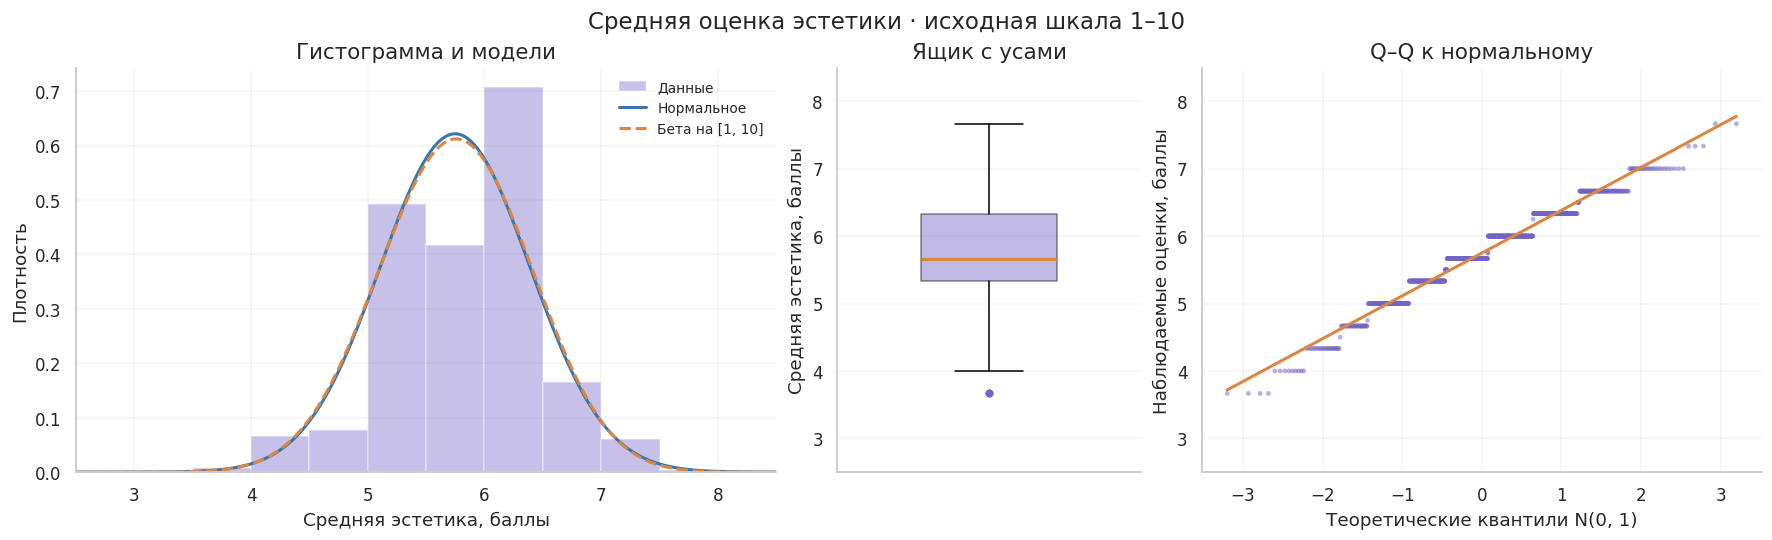

Нормальная модель: μ = 5.748, σ = 0.642
Бета-модель на [1, 10]: α = 25.334, β = 22.701


In [ ]:
# Все расчёты выполняются по средним оценкам экранов
v = screens["aesthetics_mean"].dropna().to_numpy()
mu, sigma = stats.norm.fit(v)
# Границы шкалы фиксированы: loc=1, scale=9, то есть [1, 10]
a, b, loc, scale = stats.beta.fit(v, floc=1, fscale=9)

print(f"Нормальная модель: μ = {mu:.3f}, σ = {sigma:.3f}")
print(f"Бета-модель на [1, 10]: α = {a:.3f}, β = {b:.3f}")

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.8),
    gridspec_kw={"width_ratios": [1.5, 0.65, 1.2]},
    constrained_layout=True
)
color, accent = "#7463C7", "#DB8744"
lo = max(1, np.floor(v.min()) - 0.5)
hi = min(10, np.ceil(v.max()) + 0.5)
grid = np.linspace(lo, hi, 600)
q1, q3 = np.quantile(v, [0.25, 0.75])

axes[0].hist(v, bins=np.arange(lo, hi + 0.25, 0.5), density=True,
             color=color, alpha=0.4, edgecolor="white", label="Данные")
axes[0].plot(grid, stats.norm.pdf(grid, mu, sigma),
             color="#3976AB", lw=2, label="Нормальное")
axes[0].plot(grid, stats.beta.pdf(grid, a, b, loc=loc, scale=scale),
             color=accent, lw=2, linestyle="--", label="Бета на [1, 10]")
axes[0].set(title="Гистограмма и модели", xlabel="Средняя эстетика, баллы",
            ylabel="Плотность", xlim=(lo, hi))
axes[0].legend(frameon=False, fontsize=9)

axes[1].boxplot(v, vert=True, widths=0.45, patch_artist=True,
    boxprops={"facecolor": color, "alpha": 0.45},
    medianprops={"color": accent, "linewidth": 2},
    flierprops={"marker": "o", "markersize": 4,
                "markerfacecolor": color, "markeredgecolor": color})
axes[1].set(title="Ящик с усами", ylabel="Средняя эстетика, баллы", ylim=(lo, hi))
axes[1].set_xticks([])

(theoretical, observed), (slope, intercept, _) = stats.probplot(v, dist="norm")
axes[2].scatter(theoretical, observed, s=10, color=color, alpha=0.5, edgecolors="none")
axes[2].plot(theoretical, intercept + slope * theoretical, color=accent, lw=2)
axes[2].set(title="Q–Q к нормальному", xlabel="Теоретические квантили N(0, 1)",
            ylabel="Наблюдаемые оценки, баллы", ylim=(lo, hi))
for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("Средняя оценка эстетики · исходная шкала 1–10", fontsize=15)
plt.show()

#### **Выводы по эстетике**

По таблице мы можем увидеть, что исследованы 1000 экранов, каждый с одинаковым весом. Средняя оценка эстетики составляет 5.748, медиана — 5.667 балла(можем заметить, что значения достаточно близки друг к другу). Центральные 50% наблюдений находятся между 5.333 и 6.333 балла, те центральную часть распределения показывает сам ящик между квартилями, хотя расстояние между квартилями составляет всего 1 балл. У самого ящика большая часть значений сконцентрированы внутри, но ниже нижнего уса видна отдельная точка, которая показывает значение оценки экрана, отличное от общей части, и эта оценка достаточно низкая.

Асиметричность -0.309 показывает небольшой перекос в сторону низких оценок: нижний хвост несколько выраженнее, но при этом визуально график близок к симметричному

Что касается гистограммы, самый высокий столбик сосредоточен в районе 6-6.5 баллов, те максимальное колчиество экранов получили оценку в этом диапозоне. Форма моделей и самого графика в целом совпадает, но не идеально, но все равно в отличие от формы колокола и бета-модели у гистограммы есть 2 локальные пики, но их выраженность зависит от разбиения на интервалы

На графике Q-Q значения имеют ступенчатый вид, поскольку оценки повторяются, а также они максимально приближены к прямой, но крайние значения имеют небольшие отклонения, особенно в нижней части(возможно это связано как раз с нашей ассиметричностью, которая как раз имеет небольшой перекос именно в этой части). Это говорит нам о том, что значения максимально похоже на нормальное, но опять же график не гарантирует ее

### **3.2. EDA & Distribution средней оценки удобства**

Изучим среднюю оценку удобства случайно выбранного экрана:
её типичные значения, разброс и форму распределения.

Каждое наблюдение соответствует одному экрану.
Рассматриваем экспертную оценку удобства по изображению интерфейса, а не результаты измерения скорости выполнения задач пользователями.

#### **Описательные статистики**

Аналогично эстетике измерим те же показатели у удобства интерфейса

In [ ]:
y = screens["usability_mean"].dropna()

usability_summary = pd.Series({
    "Количество экранов": y.count(),
    "Среднее": y.mean(),
    "Медиана": y.median(),
    "Стандартное отклонение": y.std(ddof=1),
    "Выборочная дисперсия": y.var(ddof=1),
    "Минимум": y.min(),
    "Первый квартиль (Q1)": y.quantile(0.25),
    "Третий квартиль (Q3)": y.quantile(0.75),
    "Максимум": y.max(),
    "Межквартильный размах (IQR)": (
        y.quantile(0.75) - y.quantile(0.25)
    ),
    "Асимметрия": y.skew(),
}, name="Средняя оценка удобства")

display(usability_summary.to_frame().round(3))

,Средняя оценка удобства
Количество экранов,1000.000
Среднее,5.816
Медиана,5.667
Стандартное отклонение,0.643
Выборочная дисперсия,0.414
Минимум,3.333
Первый квартиль (Q1),5.333
Третий квартиль (Q3),6.333
Максимум,7.667
Межквартильный размах (IQR),1.000


#### **Распределение: гистограмма с моделями, boxplot и Q–Q**

На гистограмме сравним данные с нормальной и бета-моделями.
Границы бета-распределения фиксируем по исходной шкале: от 1 до 10.
Обе модели являются непрерывными приближениями дискретных средних оценок.

Boxplot покажет медиану, квартили и наблюдения за пределами усов.
Q–Q позволит оценить, где форма распределения отличается от нормальной.

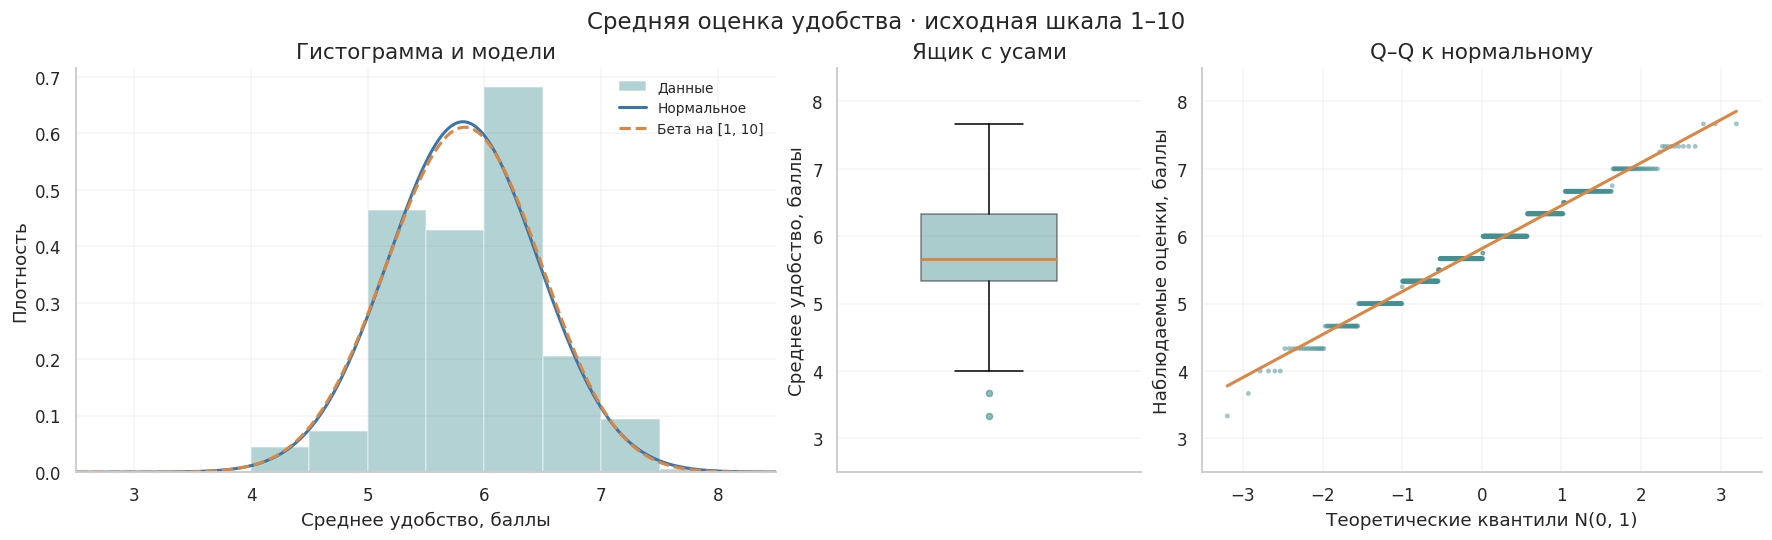

Нормальная модель: μ = 5.816, σ = 0.643
Бета-модель на [1, 10]: α = 25.525, β = 22.179


In [ ]:
from scipy import stats

u_values = y.to_numpy()

# Подбираем параметры моделей по данным
u_mu, u_sigma = stats.norm.fit(u_values)

# Бета-модель с фиксированными границами [1, 10]
u_a, u_b, u_loc, u_scale = stats.beta.fit(
    u_values,
    floc=1,
    fscale=9
)

print(
    f"Нормальная модель: "
    f"μ = {u_mu:.3f}, σ = {u_sigma:.3f}"
)
print(
    f"Бета-модель на [1, 10]: "
    f"α = {u_a:.3f}, β = {u_b:.3f}"
)

# Общий диапазон для сравнения с эстетикой
both_values = screens[
    ["aesthetics_mean", "usability_mean"]
].to_numpy()

plot_lower = max(1, np.floor(np.nanmin(both_values)) - 0.5)
plot_upper = min(10, np.ceil(np.nanmax(both_values)) + 0.5)

u_grid = np.linspace(plot_lower, plot_upper, 600)
u_bins = np.arange(plot_lower, plot_upper + 0.25, 0.5)

color = "#438F92"
accent = "#DB8744"

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
    gridspec_kw={"width_ratios": [1.5, 0.65, 1.2]},
    constrained_layout=True
)

# 1. Гистограмма и теоретические модели
axes[0].hist(
    u_values,
    bins=u_bins,
    density=True,
    color=color,
    alpha=0.4,
    edgecolor="white",
    label="Данные"
)

axes[0].plot(
    u_grid,
    stats.norm.pdf(u_grid, u_mu, u_sigma),
    color="#3976AB",
    linewidth=2,
    label="Нормальное"
)

axes[0].plot(
    u_grid,
    stats.beta.pdf(
        u_grid, u_a, u_b,
        loc=u_loc,
        scale=u_scale
    ),
    color=accent,
    linewidth=2,
    linestyle="--",
    label="Бета на [1, 10]"
)

axes[0].set(
    title="Гистограмма и модели",
    xlabel="Среднее удобство, баллы",
    ylabel="Плотность",
    xlim=(plot_lower, plot_upper)
)
axes[0].legend(frameon=False, fontsize=9)

# 2. Boxplot
axes[1].boxplot(
    u_values,
    vert=True,
    widths=0.45,
    patch_artist=True,
    boxprops={
        "facecolor": color,
        "alpha": 0.45
    },
    medianprops={
        "color": accent,
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "markerfacecolor": color,
        "markeredgecolor": color,
        "alpha": 0.6
    }
)

axes[1].set(
    title="Ящик с усами",
    ylabel="Среднее удобство, баллы",
    ylim=(plot_lower, plot_upper)
)
axes[1].set_xticks([])

# 3. Q–Q к нормальному распределению
(u_theoretical, u_observed), (
    u_slope, u_intercept, _
) = stats.probplot(u_values, dist="norm")

axes[2].scatter(
    u_theoretical,
    u_observed,
    s=10,
    color=color,
    alpha=0.5,
    edgecolors="none"
)

axes[2].plot(
    u_theoretical,
    u_intercept + u_slope * u_theoretical,
    color=accent,
    linewidth=2
)

axes[2].set(
    title="Q–Q к нормальному",
    xlabel="Теоретические квантили N(0, 1)",
    ylabel="Наблюдаемые оценки, баллы",
    ylim=(plot_lower, plot_upper)
)

for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Средняя оценка удобства · исходная шкала 1–10",
    fontsize=15
)

plt.show()

#### **Выводы по удобству**

Настолько подробно расписывать этот график не имеет смысла, поскольку он максимально похож на предыдущий: и по значениям, и по визуальной составляющей

Хочется отметить, что у ящика с усами значения буквально совпадают с эстетикой, но при этом ниже усов видны уже 2 отдельные точки, которые отображают оценку меньше основной массы.

Асиметрия у удобства ниже - удобство чуть симметричнее эстетики, что особенно заметно на графике Q-Q

Также у гистограммы удобства 2 пика выражены меньше, чем у эстетики, при этом форма нормальной и бета-модели также остаются приближенными. Самый высокий столбик снова соответствует интервалу 6–6,5 балла





### 3.3. **Проверка нормальности и численное сравнение моделей**

Можно также дополнить визуальное сравнение численными характеристиками, для этого проверяем оба показателя на уровне средних оценок экранов с помощью Шапиро — Уилка. До этого мы оценивали по гистограмме совпадение, а сейчас проверим согласованность наших данных с этим нормальным распределением

**Шапиро — Уилк:** $H_0$ — распределение нормальное; $H_1$ — отличается от нормального. Используем $\alpha = 0{,}05$ и поправку Холма для двух проверок. Оценки дискретны и ограничены, поэтому нормальная модель — лишь приближение. Отклонение $H_0$ не запрещает её использование для описания данных или расчёт корреляций.

**Сравнение моделей:** рассматриваем нормальное и бета-распределение с фиксированными границами $[1, 10]$.

$$
\mathrm{AIC} = 2k - 2\ln \hat{L},
$$

где $k = 2$ для обеих моделей, а $\hat{L}$ — максимальное правдоподобие. Меньший AIC предпочтительнее при сравнении моделей одного показателя. Для дискретных оценок это описательное сравнение непрерывных приближений, а не поиск истинного распределения.

**Расстояние между распределениями:**

$$
D = \sup_x \left|F_n(x) - F_{\hat{\theta}}(x)\right|,
$$

где $F_n$ — эмпирическая функция распределения, а $F_{\hat{\theta}}$ — подобранная модель. Чем меньше $D$, тем ближе распределения. Стандартное p-value теста KS не используем из-за оценки параметров на тех же данных и повторяющихся значений.

Обе метрики описывают подгонку на исходных данных. Проверки предполагают независимость экранов; возможные связи через приложения и оценщиков остаются ограничением.

In [ ]:
distribution_test_rows, model_comparison_rows = [], []
for metric_name, column in {"Эстетика": "aesthetics_mean", "Удобство": "usability_mean"}.items():
    values = screens[column].dropna().to_numpy()
    shapiro_result = stats.shapiro(values)
    distribution_test_rows.append({"Показатель": metric_name, "n": len(values),
        "W": shapiro_result.statistic, "p-value": shapiro_result.pvalue})
    normal_params = stats.norm.fit(values)
    beta_params = stats.beta.fit(values, floc=1, fscale=9)
    sorted_values = np.sort(values)
    for model_name, distribution, params in [
        ("Нормальное", stats.norm, normal_params),
        ("Бета [1, 10]", stats.beta, beta_params)]:
        log_likelihood = distribution.logpdf(values, *params).sum()
        fitted_cdf = distribution.cdf(sorted_values, *params)
        # Максимальное расхождение с правой и левой границами ступеней ECDF.
        d_plus = np.max(np.arange(1, len(values)+1)/len(values) - fitted_cdf)
        d_minus = np.max(fitted_cdf - np.arange(len(values))/len(values))
        model_comparison_rows.append({"Показатель": metric_name, "Модель": model_name,
            "Оцениваемых параметров k": 2, "AIC (непрерывное приближение)": 4-2*log_likelihood,
            "Расстояние D": max(d_plus, d_minus)})
distribution_tests = pd.DataFrame(distribution_test_rows)
pvals = distribution_tests["p-value"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
adjusted[order] = np.minimum(1, np.maximum.accumulate(
    (len(pvals)-np.arange(len(pvals))) * pvals[order]))
distribution_tests["p-value Холма"] = adjusted
distribution_tests["Отвергаем нормальность"] = adjusted < .05
model_comparisons = pd.DataFrame(model_comparison_rows)
model_comparisons["ΔAIC внутри показателя"] = (
    model_comparisons["AIC (непрерывное приближение)"]
    - model_comparisons.groupby("Показатель")["AIC (непрерывное приближение)"].transform("min"))
distribution_display = distribution_tests.copy()
for p_column in ["p-value", "p-value Холма"]:
    distribution_display[p_column] = distribution_display[p_column].map(lambda value: f"{value:.3e}")
display(distribution_display)
display(model_comparisons.round(4))

,Показатель,n,W,p-value,p-value Холма,Отвергаем нормальность
0,Эстетика,1000,0.972162,6.417e-13,1.283e-12,True
1,Удобство,1000,0.976766,1.481e-11,1.481e-11,True


,Показатель,Модель,Оцениваемых параметров k,AIC (непрерывное приближение),Расстояние D,ΔAIC внутри показателя
0,Эстетика,Нормальное,2,1954.8657,0.1217,1.1854
1,Эстетика,"Бета [1, 10]",2,1953.6803,0.1187,0.0000
2,Удобство,Нормальное,2,1958.6139,0.1091,0.2121
3,Удобство,"Бета [1, 10]",2,1958.4018,0.1083,0.0000


####**Вывод**

График действительно имеет некоторую схожесть визуально с нормальным распределением, но по таблицам мы видим, что показатель p-value заметно ниже нашего порога 0.05, поэтому нормальность мы отрицаем

На второй таблице мы сравниваем нормальную и бета-модели по AIC и D. У бета-распределения оба значения немного меньше, однако различия
между моделями невелики. Поэтому рассматриваем их как приближённое
описание распределений средних оценок.

### **Общие выводы по эстетике и удобству**

Хочется в первую очередь отметить, что графики эстетики и удобства и по значениям, и визуально очень похожи друг на друга: у них близкие центр, разброс и форма, а некоторые числовые характеристики совпадают.  Оба распределения визуально близки к симметричным, с небольшим перекосом в сторону низких оценок, где у удобства этот перекос выражен слабее. Несмотря на то, что графики очень похожи между собой, это не доказывает их зависимость. Также благодаря проверки нормальности мы убедились в том, что несмотря на визуальное соответствие гистограмм с нормальным распределением, гипотеза нормальности отвергается для обоих показателей, так что модели просто дают приближенное описание данных.

Чтобы не предполагать на схожести данных о их зависимости, тк это вообще не является достоверным подтверждением гипотезы, на следующем этапе исследуем зависимость, сопоставляя пары оценок каждого экрана

<a id="dependence"></a>
## **4. Зависимость эстетики и удобства**

Проверим, связана ли средняя оценка эстетики экрана со средней оценкой его удобства.

Каждая точка соответствует одному экрану:
- по горизонтали — средняя оценка эстетики;
- по вертикали — средняя оценка удобства.

Точки полупрозрачные: чем темнее место на графике, тем больше экранов с такой парой средних оценок.

МНК — метод наименьших квадратов: он подбирает прямую, минимизируя сумму квадратов вертикальных отклонений точек.

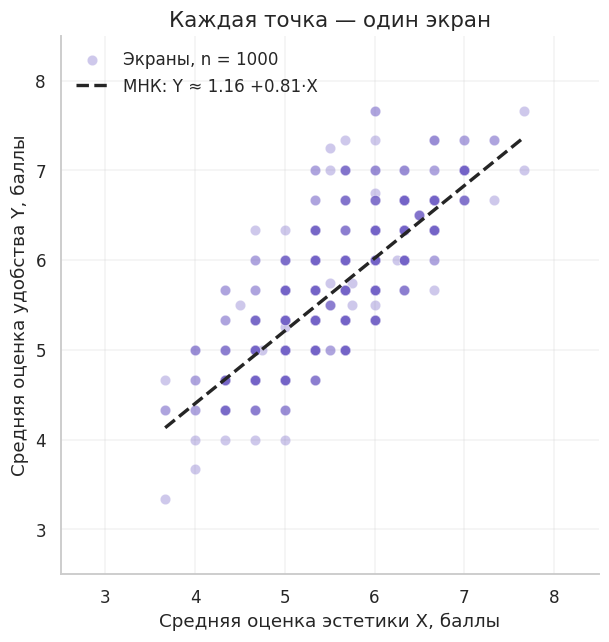

In [ ]:
# Сохраняем пары оценок одних и тех же экранов
dependence_data = screens[
    ["aesthetics_mean", "usability_mean"]
].dropna()

dep_x = dependence_data["aesthetics_mean"].to_numpy()
dep_y = dependence_data["usability_mean"].to_numpy()

# Линейная регрессия: Y ≈ intercept + slope * X
regression = stats.linregress(dep_x, dep_y)

line_x = np.linspace(dep_x.min(), dep_x.max(), 200)
line_y = regression.intercept + regression.slope * line_x

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    dep_x,
    dep_y,
    s=45,
    color="#7463C7",
    alpha=0.35,
    edgecolors="white",
    linewidths=0.4,
    label=f"Экраны, n = {len(dependence_data)}"
)

ax.plot(
    line_x,
    line_y,
    color="#252525",
    linestyle="--",
    linewidth=2.2,
    label=(
        f"МНК: Y ≈ {regression.intercept:.2f} "
        f"{regression.slope:+.2f}·X"
    )
)

lower = max(1, np.floor(min(dep_x.min(), dep_y.min())) - 0.5)
upper = min(10, np.ceil(max(dep_x.max(), dep_y.max())) + 0.5)

ax.set(
    title="Каждая точка — один экран",
    xlabel="Средняя оценка эстетики X, баллы",
    ylabel="Средняя оценка удобства Y, баллы",
    xlim=(lower, upper),
    ylim=(lower, upper)
)

ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

####**Что показывает этот график?**

Мы видим, что точки удобства и эстетики находятся в одном облаке. Но что интересно, облако имеет вытянутую форму и мы можем увидеть, что наиболее высокие и низкие оценки стоят рядом. То есть экраны с более высокой средней оценкой эстетики обычно имеют и более высокую среднюю оценку удобства

In [ ]:
display(dependence_data.corr(method="pearson"))

,aesthetics_mean,usability_mean
aesthetics_mean,1.000000,0.807924
usability_mean,0.807924,1.000000


####**Вывод о марице корреляций**

**Пирсон $r = 0{,}808$** оценивает линейную связь: насколько облако вытянуто вдоль прямой.

**Спирмен $\rho = 0{,}805$** сравнивает порядок экранов по оценкам: занимают ли более эстетичные экраны также более высокие места по удобству.

Из этих показателей мы можем сделать вывод о том, что значения эстетики и удобства показывают положительную связь, поскольку значения приближены к 1. НО здесь связаны записанные средние оценки, её происхождение и влияние красоты на удобство этим не доказаны, тут нам поможет проверка разных аннотаций, которая уточняет, как эту связь интерпретировать

In [ ]:
# Корректные пары: одна строка — один экран
test_pairs = screens[
    ["aesthetics_mean", "usability_mean"]
].dropna()

# Спирмен — это корреляция Пирсона между рангами.
# Совпадающим значениям присваиваются средние ранги.
rank_x = stats.rankdata(test_pairs["aesthetics_mean"])
rank_y = stats.rankdata(test_pairs["usability_mean"])

# Центрируем ранги
rank_x = rank_x - rank_x.mean()
rank_y = rank_y - rank_y.mean()

denominator = np.linalg.norm(rank_x) * np.linalg.norm(rank_y)

if denominator == 0:
    raise ValueError(
        "Проверка невозможна: один из показателей постоянный."
    )

observed_rho = np.dot(rank_x, rank_y) / denominator

# Отдельный генератор для воспроизводимости проверки
permutation_rng = np.random.default_rng(SEED)

n_permutations = 9999
null_correlations = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled_y = permutation_rng.permutation(rank_y)

    null_correlations[i] = (
        np.dot(rank_x, shuffled_y) / denominator
    )

# Двусторонняя проверка с поправкой +1:
# оценка p-value не может оказаться равной нулю.
n_extreme = np.count_nonzero(
    np.abs(null_correlations) >= abs(observed_rho) - 1e-12
)

permutation_p = (n_extreme + 1) / (n_permutations + 1)
alpha = 0.05

print(f"Количество экранов: {len(test_pairs)}")
print(f"Наблюдаемая корреляция Спирмена: {observed_rho:.4f}")
print(f"Количество перестановок: {n_permutations}")
print(f"Двустороннее p-value: {permutation_p:.4f}")

if permutation_p < alpha:
    print(
        "Отвергаем H₀ о независимости: "
        "обнаружена статистически значимая связь."
    )
else:
    print(
        "Нет оснований отвергнуть H₀ о независимости. "
        "Это не доказывает независимость."
    )

Количество экранов: 1000
Наблюдаемая корреляция Спирмена: 0.8048
Количество перестановок: 9999
Двустороннее p-value: 0.0001
Отвергаем H₀ о независимости: обнаружена статистически значимая связь.


А это перестановочный тест. Он показывает, что при предположении независимости экранов наблюдаемую связь трудно объяснить случайным сопоставлением оценок: p = 0,0001 < 0,05.

### 4.1. Связаны ли две оценки внутри одной аннотации?

Средняя эстетика и среднее удобство одного экрана используют оценки из одних и тех же строк, из-за чего их корреляция может отражать как различия экранов, так и связь двух баллов внутри одной аннотации, поэтому для установки связи разделим эти источники

Сравним:
1. Средние эстетики и удобства экранов — исходный результат.
2. Эстетику и удобство внутри одной строки аннотации.
3. Эстетику одной строки и удобство другой строки того же экрана.
4. Эстетику разных строк одного экрана.

Для главного сопоставления оставим экраны с **ровно тремя** строками. Тогда каждый экран даёт одинаковое число пар: три внутристрочных и шесть упорядоченных межстрочных. Дополнительно покажем результаты на всех доступных строках: там экраны с большим числом аннотаций получают больший вес в межстрочной корреляции.

В CSV нет ID эксперта. Поэтому «другая аннотация» — другая строка, а не проверенный по идентификатору другой человек. По описанию выпуска экран оценивали разные аннотаторы, но неодинаковое число строк требует осторожности. Межстрочные пары зависимы; не вычисляем p-value так, будто каждая пара независима.

Четвёртая корреляция описывает согласованность ранжирования в построенных парах, но **не является полноценным коэффициентом межэкспертного согласия**. Для оценки личной строгости и надёжности оценщиков нужны их идентификаторы и подходящая модель.


,Набор,Сравнение,Пар,Спирмен ρ
0,Ровно 3 аннотации,Средние экранов: эстетика — удобство,966,0.8062
1,Ровно 3 аннотации,Одна строка: эстетика — удобство,2898,0.8126
2,Ровно 3 аннотации,Разные строки экрана: эстетика — удобство,5796,0.0386
3,Ровно 3 аннотации,Разные строки экрана: эстетика — эстетика,5796,0.0328
4,Все строки,Средние экранов: эстетика — удобство,1000,0.8048
5,Все строки,Одна строка: эстетика — удобство,2981,0.8112
6,Все строки,Разные строки экрана: эстетика — удобство,5942,0.0349
7,Все строки,Разные строки экрана: эстетика — эстетика,5942,0.0277


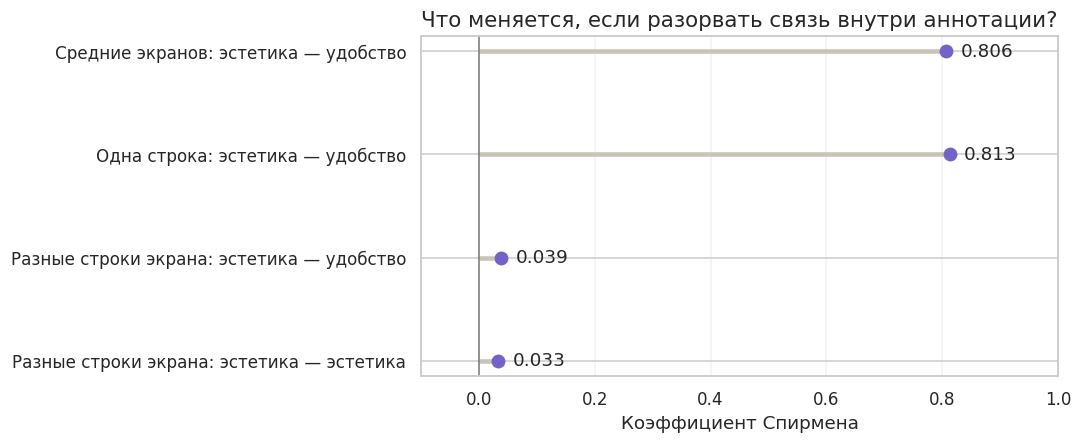

Экранов с ровно тремя строками: 966


In [ ]:
def annotation_correlations(frame, label):
    averages = frame.groupby("rico_id")[["aesthetics_rating", "usability_rating"]].mean()
    cross_a, cross_u, other_a = [], [], []
    for _, group in frame.groupby("rico_id"):
        aesthetics = group.aesthetics_rating.to_numpy()
        usability = group.usability_rating.to_numpy()
        for first in range(len(group)):
            for second in range(len(group)):
                if first != second:
                    cross_a.append(aesthetics[first])
                    cross_u.append(usability[second])
                    other_a.append(aesthetics[second])
    same_rho = stats.spearmanr(frame.aesthetics_rating, frame.usability_rating).statistic
    return [
        {"Набор": label, "Сравнение": "Средние экранов: эстетика — удобство",
         "Пар": len(averages), "Спирмен ρ": stats.spearmanr(averages.iloc[:,0], averages.iloc[:,1]).statistic},
        {"Набор": label, "Сравнение": "Одна строка: эстетика — удобство",
         "Пар": len(frame), "Спирмен ρ": same_rho},
        {"Набор": label, "Сравнение": "Разные строки экрана: эстетика — удобство",
         "Пар": len(cross_a), "Спирмен ρ": stats.spearmanr(cross_a, cross_u).statistic},
        {"Набор": label, "Сравнение": "Разные строки экрана: эстетика — эстетика",
         "Пар": len(cross_a), "Спирмен ρ": stats.spearmanr(cross_a, other_a).statistic},
    ]
annotation_counts = df.groupby("rico_id").size()
three_ids = annotation_counts[annotation_counts == 3].index
three_rows = df[df.rico_id.isin(three_ids)]
annotation_results = pd.DataFrame(
    annotation_correlations(three_rows, "Ровно 3 аннотации")
    + annotation_correlations(df, "Все строки"))
print("Экранов с ровно тремя строками:", len(three_ids))
display(annotation_results.round(4))

comparison_plot = annotation_results[annotation_results.Набор == "Ровно 3 аннотации"]
fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(comparison_plot))
ax.hlines(positions, 0, comparison_plot["Спирмен ρ"], color="#C9C4B8", linewidth=3)
ax.scatter(comparison_plot["Спирмен ρ"], positions, color="#7463C7", s=65, zorder=3)
for pos, value in zip(positions, comparison_plot["Спирмен ρ"]):
    ax.text(value+.025, pos, f"{value:.3f}", va="center")
ax.set_yticks(positions, comparison_plot.Сравнение)
ax.set(xlim=(-.1, 1), xlabel="Коэффициент Спирмена",
       title="Что меняется, если разорвать связь внутри аннотации?")
ax.invert_yaxis()
ax.axvline(0, color="#777777", linewidth=1)
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

####**Вывод**

Этот график показывает, что сильная связь видна внутри одной аннотации, но почти исчезает, если сопоставлять разные аннотации одного экрана. То есть эстетика и удобство связаны прежде всего в оценках одного и того же аннотатора, а между оценками разных аннотаторов корреляция близка к нулю.

### **Вывод о зависимости 2 величин**

На основе исследования мы можем сделать вывод, что средние оценки эстетики и удобства экранов имеют сильную положительную связь. Перестановочный тест подтверждает её статистическую значимость при предпосылке независимости экранов.

Дополнительное исследование показало, что сильная связь наблюдается и внутри одной аннотации, а при сопоставлении оценок из разных аннотаций одного экрана корреляция становится близкой к нулю. Поэтому важно учитывать, взяты ли две оценки из одной записи оценщика или из разных, потому что связь эстетики и удобства мы можем отслеживать именно в рамках оценок одного аннотатора

Почему именно так? У нас есть несколько предположений:

1. Эфферт ореола -  когда человек выстраивает общее впечатление об экране, и это влияет одновременно на оценки эстетики и удобства.
2. Человеческий фактор - это обсуждалось и до этого, но действительно показатели могут иметь связь исходя из какого-то личного опыта человека
3. Критерии оценки - каждый из аннотаторов мог по своему воспринимать критерии оценки, из-за чего связь между аннотаторами почти нулевая, а между показателями возрастает

<a id="heatmap"></a>
## **5. Тепловая карта замечаний**

**Где на экране мобильного приложения эксперты чаще всего находят проблемы?**

В UICrit к каждому замечанию эксперта приложена рамка — область экрана, к которой оно относится. Наложив 11 тысяч рамок на один силуэт телефона, получаем карту «где болит у мобильных интерфейсов», а затем проверяем увиденное статистическими критериями. Данные — таблица `df`, загруженная в разделе 1. Переключатели в разделе 5.4 работают при запуске в Colab или Jupyter.

In [ ]:
import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from matplotlib.patches import FancyBboxPatch
from scipy import stats

# Палитра C и стиль графиков заданы в начале ноутбука (раздел 1)
# Последовательная шкала для тепловых карт: фон сайта → зелёный «данные» → почти чёрный
HEAT = LinearSegmentedColormap.from_list(
    "heat",
    ["#F4F9FC", "#DCEEF8", "#ACD5EC",
     "#73B4D9", "#367FA9", "#163E59"]
)

<a id="heat-boxes"></a>
### 5.1. Разбор рамок замечаний

Столбец `comments` хранит список замечаний строкой. В конце каждого замечания записана рамка:
`Bounding Box: [x1, y1, x2, y2]` — левый верхний и правый нижний углы в долях ширины и высоты экрана
(0 — верхний левый угол, 1 — нижний правый). Поэтому рамки с разных экранов можно накладывать друг на друга.

Столбец `comments_source` хранит для каждого замечания его автора: `human` (человек), `llm` (Gemini) или `both`.

Для каждого замечания вычисляем:
- площадь рамки $A=(x_2-x_1)(y_2-y_1)$ — доля площади экрана;
- высоту центра рамки $h=\tfrac{1}{2}(y_1+y_2)$: 0 — верх экрана, 1 — низ;
- тему по ключевым словам в тексте:

| Тема | Ключевые слова (с любым окончанием) |
|---|---|
| Цвет и контраст | color, colour, contrast |
| Текст и шрифт | font, text size, readab… (readable, readability) |
| Кнопки | button |
| Иконки | icon |

Тот же словарь `THEMES` используется в разделе 6.

In [ ]:
BOX = re.compile(r"Bounding Box: \[([^\]]+)\]")
# Тема → регулярное выражение по английскому тексту замечания.
# Один словарь на разделы 5 и 6; \b — начало слова, \w* — любое окончание (colors, contrasting, icons…)
THEMES = {
    "Цвет и контраст": r"\bcolou?r\w*|\bcontrast\w*",
    "Текст и шрифт": r"\bfont\w*|\btext\s+size\b|\breadab\w*",
    "Кнопки": r"\bbutton\w*",
    "Иконки": r"\bicon\w*",
}

rows, mismatched = [], 0
for annotation, r in df.iterrows():          # annotation — номер строки = один аннотатор
    comments = ast.literal_eval(r["comments"])
    sources = ast.literal_eval(r["comments_source"])
    if len(comments) != len(sources):        # метки автора не совпадают с замечаниями
        mismatched += 1
        sources = [None] * len(comments)
    for text, src in zip(comments, sources):
        m = BOX.search(text)
        if m:
            x1, y1, x2, y2 = map(float, m.group(1).split(","))
            rows.append({"rico_id": r["rico_id"], "annotation": annotation, "source": src,
                         "x1": x1, "y1": y1, "x2": x2, "y2": y2, "text": text.lower()})

boxes = pd.DataFrame(rows)
boxes["area"] = (boxes["x2"] - boxes["x1"]) * (boxes["y2"] - boxes["y1"])
boxes["h"] = (boxes["y1"] + boxes["y2"]) / 2
for theme, pattern in THEMES.items():
    boxes[theme] = boxes["text"].str.contains(pattern, regex=True)

print("Замечаний с рамкой:", len(boxes))
print("Строк, где число меток автора не совпадает с числом замечаний:", mismatched)
print("Рамок вне [0, 1]:", int(((boxes[["x1", "y1", "x2", "y2"]] < 0) | (boxes[["x1", "y1", "x2", "y2"]] > 1)).any(axis=1).sum()))
boxes["source"].value_counts(dropna=False).rename("замечаний").to_frame()

,замечаний
source,
human,8230
both,1856
llm,1026
None,318


Замечаний с рамкой: 11430
Строк, где число меток автора не совпадает с числом замечаний: 83
Рамок вне [0, 1]: 0


**Подготовка.** У всех 11 430 замечаний есть рамка, координаты лежат в [0, 1]. В 83 строках число меток автора
не совпадает с числом замечаний — это ошибка в самом датасете. Для таких замечаний автор неизвестен (`None`),
и в сравнение «люди против ИИ» они не входят. Остальной анализ их использует.

README датасета указывает 11 344 замечания, а при разборе получается 11 430 (на 86, или 0,8%, больше). Причина в документации не описана; на выводы такое расхождение не влияет.

<a id="heat-size"></a>
### 5.2. Какие рамки брать: размер

Рамки очень разные: от одной иконки до всего экрана. Крупные рамки при наложении заливают центр
и превращают карту в размытое пятно, поэтому сначала смотрим на распределение площади.

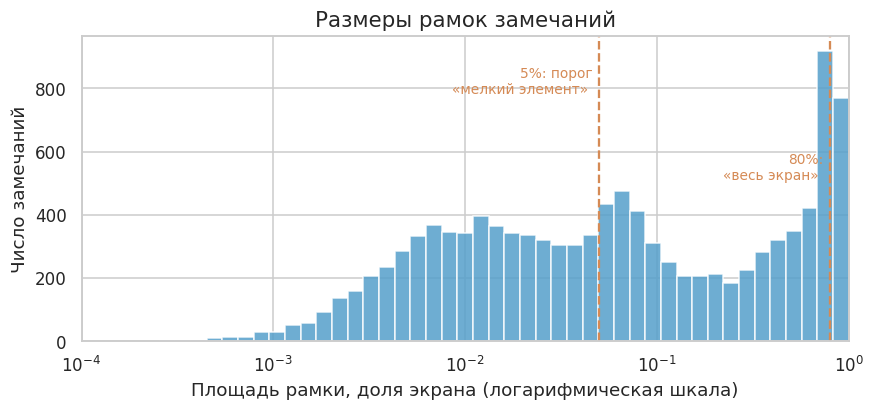

Мелкие (< 5% экрана): 5485 (48%)
Весь экран (> 80%): 1034 (9%)


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(-4, 0, 50)
ax.hist(boxes["area"][boxes["area"] > 0], bins=bins, color=C["data"], alpha=.85, edgecolor="white")
ax.set_xscale("log")
ax.set_xlim(1e-4, 1)
for t, lab, ha, y in [(0.05, "5%: порог\n«мелкий элемент» ", "right", .9), (0.8, "80%:\n«весь экран» ", "right", .62)]:
    ax.axvline(t, color=C["ref"], lw=1.5, ls="--")
    ax.text(t * 0.92, ax.get_ylim()[1] * y, lab, color=C["ref"], fontsize=9, ha=ha, va="top")
ax.set(xlabel="Площадь рамки, доля экрана (логарифмическая шкала)", ylabel="Число замечаний",
       title="Размеры рамок замечаний")
plt.show()

small = boxes[boxes["area"] < 0.05]
print(f"Мелкие (< 5% экрана): {len(small)} ({len(small) / len(boxes):.0%})")
print(f"Весь экран (> 80%): {(boxes['area'] > 0.8).sum()} ({(boxes['area'] > 0.8).mean():.0%})")

На гистограмме видно два горба: много маленьких рамок (около 1% экрана) и много рамок почти во весь экран. Похоже, эксперты критикуют двумя способами: указывают на конкретный элемент или говорят про экран в целом. Для тепловой карты мы взяли только маленькие рамки, меньше 5% экрана. Это почти половина всех замечаний, и именно они показывают, где находится проблема.

<a id="heat-main"></a>
### 5.3. Главная тепловая карта

Экран делим на сетку 90 × 160 клеток (пропорции 9:16). Каждая рамка добавляет +1 во все клетки, которые накрывает;
сумму делим на число замечаний. Значение клетки — **доля замечаний, задевающих эту клетку**:

$$H(c)=\frac{1}{N}\sum_{k=1}^{N}\mathbf{1}\left[c \in \text{рамка}_k\right].$$

Так карты групп с разным числом замечаний можно сравнивать между собой.

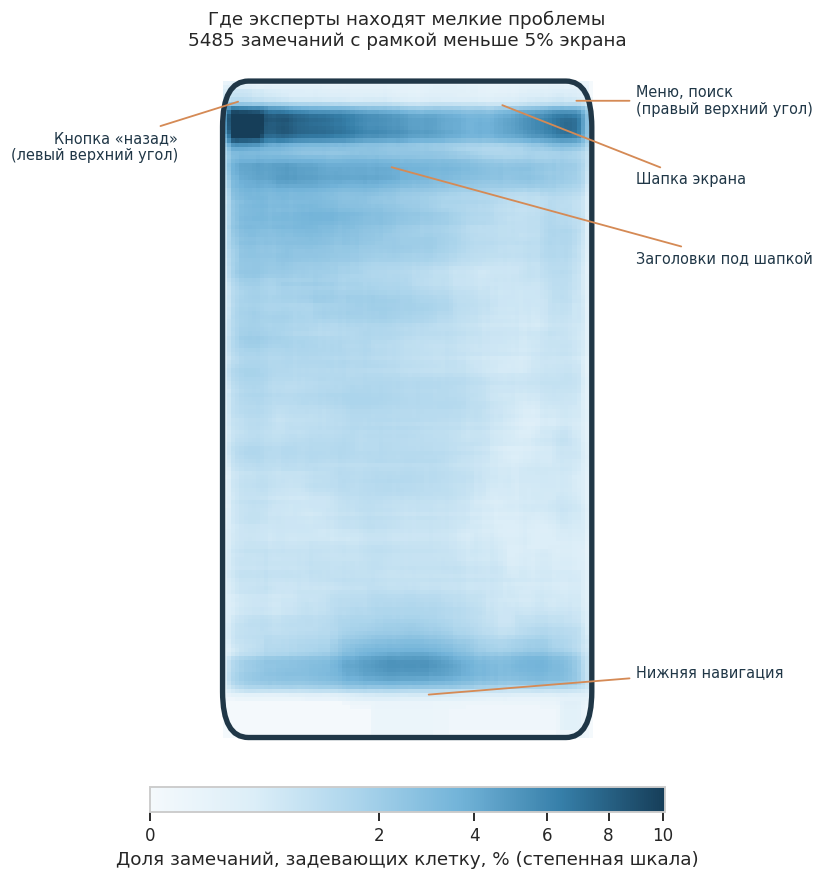

In [ ]:
W, H = 90, 160


def heat(sub):
    # Доля замечаний, задевающих каждую клетку экрана
    grid = np.zeros((H, W))
    for x1, y1, x2, y2 in sub[["x1", "y1", "x2", "y2"]].to_numpy():
        r1, c1 = int(y1 * H), int(x1 * W)
        grid[r1:max(int(y2 * H), r1 + 1), c1:max(int(x2 * W), c1 + 1)] += 1
    return grid / max(len(sub), 1)


def phone(ax, grid, title=None, vmax=None, cbar=False):
    # Тепловая карта внутри силуэта телефона; степенная шкала (γ = 0.5) проявляет слабые зоны
    vals = grid * 100
    top = vmax if vmax is not None else np.percentile(vals, 99.7)
    im = ax.imshow(vals, cmap=HEAT, extent=(0, 1, 1, 0), norm=PowerNorm(0.5, vmin=0, vmax=top))
    ax.set_aspect(16 / 9)
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.07",
                                fill=False, lw=3.5, ec=C["ink"]))
    ax.set(xlim=(-.04, 1.04), ylim=(1.04, -.04), xticks=[], yticks=[])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, loc="center", fontsize=10)
    if cbar:
        cb = plt.colorbar(im, ax=ax, orientation="horizontal", fraction=.04, pad=.03)
        cb.set_label("Доля замечаний, задевающих клетку, % (степенная шкала)")
    return im


fig, ax = plt.subplots(figsize=(9, 9))
fig.subplots_adjust(left=.24, right=.76)
phone(ax, heat(small), cbar=True)
notes = [((0.05, 0.03), (-0.12, 0.10), "Кнопка «назад»\n(левый верхний угол)", "right"),
         ((0.95, 0.03), (1.12, 0.03), "Меню, поиск\n(правый верхний угол)", "left"),
         ((0.75, 0.035), (1.12, 0.15), "Шапка экрана", "left"),
         ((0.45, 0.13), (1.12, 0.27), "Заголовки под шапкой", "left"),
         ((0.55, 0.935), (1.12, 0.90), "Нижняя навигация", "left")]
for xy, xytext, text, ha in notes:
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=9.5, color=C["ink"], ha=ha, va="center",
                arrowprops=dict(arrowstyle="-", color=C["ref"], lw=1.2), annotation_clip=False)
ax.set_title(f"Где эксперты находят мелкие проблемы\n{len(small)} замечаний с рамкой меньше 5% экрана",
             loc="center", fontsize=12)
plt.show()

**Что видно.** Самые критикуемые мелкие места — не контент посередине, а **края экрана**:
две яркие точки в верхних углах (кнопка «назад» слева, меню или поиск справа), полоса шапки сверху
и полоса нижней навигации снизу. Ниже шапки — более слабое пятно: заголовки и первые строки контента.

<a id="heat-compare"></a>
### 5.4. Сравнение: люди и ИИ, темы замечаний

Все карты в этом разделе на одной шкале цвета, поэтому их можно сравнивать между собой.
Темы определены по ключевым словам, и одно замечание может попасть в несколько тем.

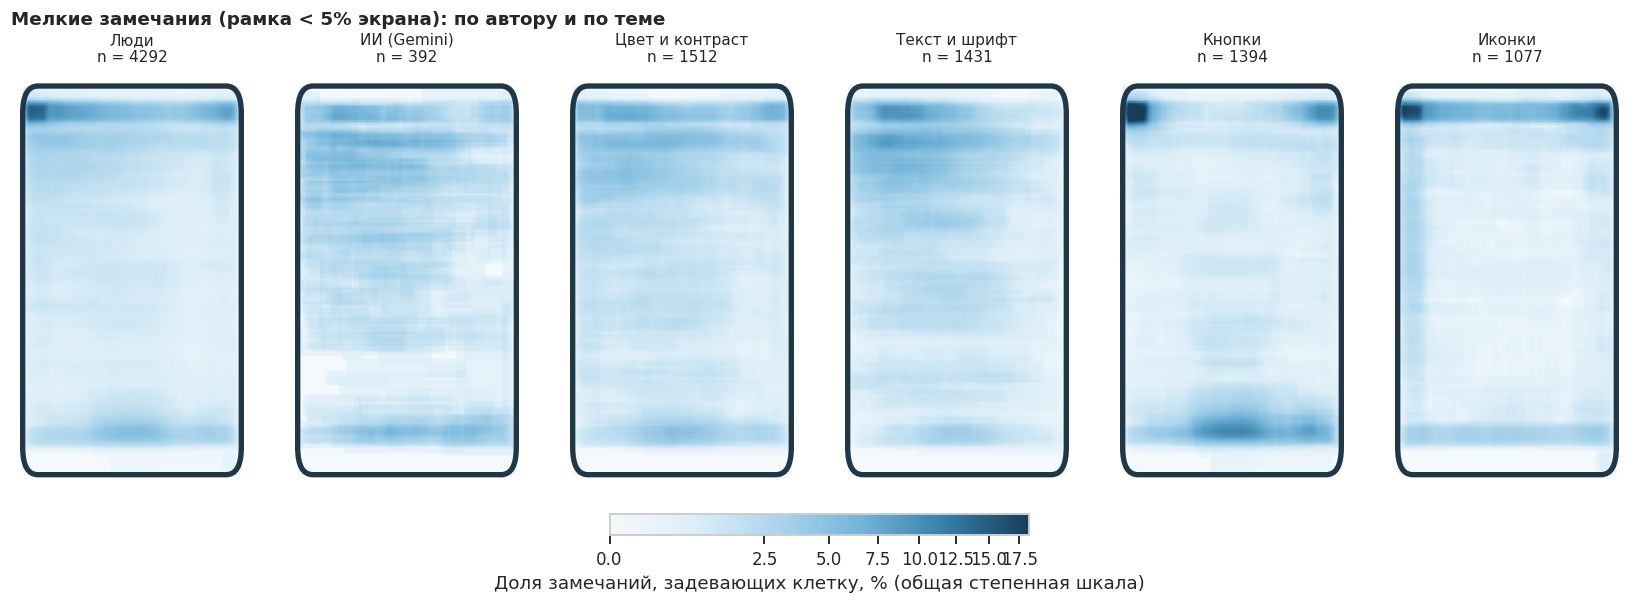

In [ ]:
groups = [("Люди", small[small["source"] == "human"]), ("ИИ (Gemini)", small[small["source"] == "llm"])]
groups += [(t, small[small[t]]) for t in THEMES]
grids = [(name, sub, heat(sub)) for name, sub in groups]
vmax = max(np.percentile(g * 100, 99.7) for _, _, g in grids)

fig, axs = plt.subplots(1, len(grids), figsize=(15, 5.4), layout="constrained")
for ax, (name, sub, g) in zip(axs, grids):
    im = phone(ax, g, f"{name}\nn = {len(sub)}", vmax=vmax)
cb = fig.colorbar(im, ax=axs, orientation="horizontal", fraction=.05, shrink=.5)
cb.set_label("Доля замечаний, задевающих клетку, % (общая степенная шкала)")
fig.suptitle("Мелкие замечания (рамка < 5% экрана): по автору и по теме", x=.01, ha="left",
             fontsize=12, fontweight="bold")
plt.show()

**Что видно.**
- **Люди** сосредоточены на углах и шапке. У **ИИ** карта «полосатая» и разбросана по всему экрану:
  Gemini чаще комментирует строки контента посередине. Карта ИИ шумнее ещё и потому, что мелких замечаний ИИ
  намного меньше (392 против 4 292 у людей).
- **Кнопки** — верхние углы и нижняя навигация. **Иконки** — почти только шапка.
- **Текст** и **цвет** — по всему экрану, больше всего в верхней части контента, сразу под шапкой.
  Сама шапка на этих картах выделяется, но по количеству замечаний про текст и цвет там меньше, чем в контенте (см. 5.5.3).


#### Как размер рамки меняет картину

Чем крупнее рамки берём, тем сильнее карта размывается в пятно.

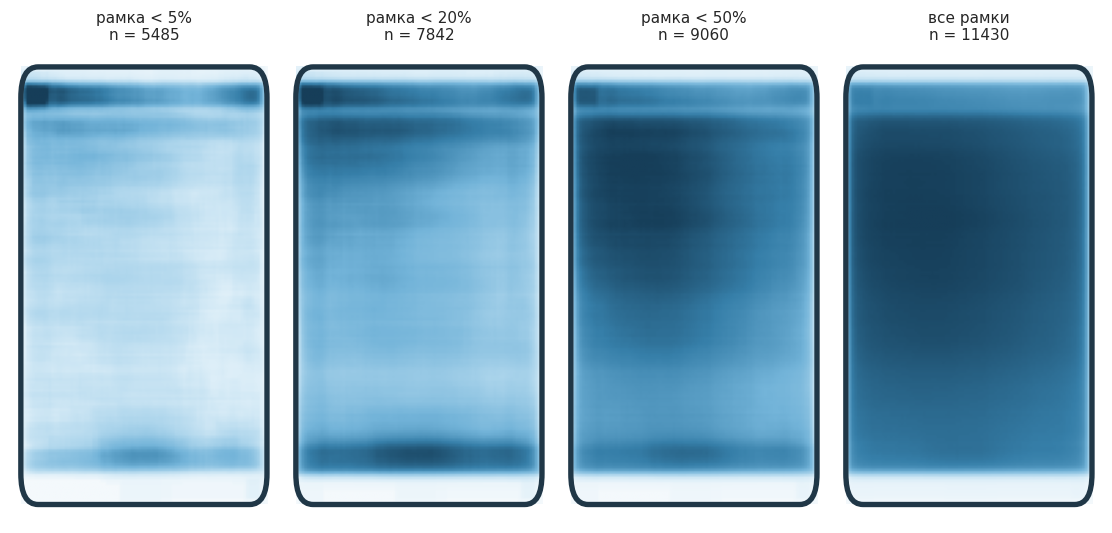

In [ ]:
limits = [0.05, 0.2, 0.5, 1.01]
fig, axs = plt.subplots(1, len(limits), figsize=(10, 5), layout="constrained")
for ax, lim in zip(axs, limits):
    sub = boxes[boxes["area"] < lim]
    label = "все рамки" if lim > 1 else f"рамка < {lim:.0%}"
    phone(ax, heat(sub), f"{label}\nn = {len(sub)}")
plt.show()

Чем крупнее рамки мы добавляем, тем сильнее карта расплывается в одно пятно, и углы, шапка и навигация перестают быть видны. Поэтому для поиска конкретных проблемных мест мы оставили только маленькие рамки. (Цвет на каждой из этих карт подобран отдельно, поэтому сравнивать здесь нужно форму пятен, а не их яркость.)

**Интерактивная версия** (работает при запуске в Colab или Jupyter): переключатели автора и темы и слайдер порога размера рамки.

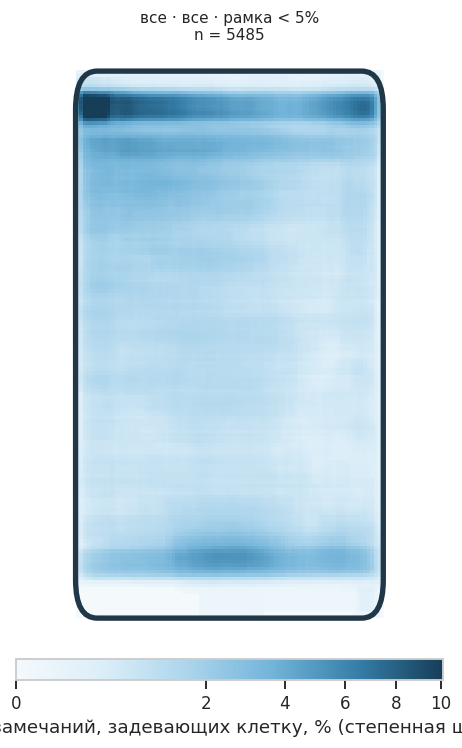

In [ ]:
import ipywidgets as widgets


def explore(автор="все", тема="все", порог=0.05):
    sub = boxes[boxes["area"] < порог]
    if автор != "все":
        sub = sub[sub["source"] == {"люди": "human", "ИИ": "llm", "оба": "both"}[автор]]
    if тема != "все":
        sub = sub[sub[тема]]
    fig, ax = plt.subplots(figsize=(5, 7.5))
    phone(ax, heat(sub), f"{автор} · {тема} · рамка < {порог:.0%}\nn = {len(sub)}", cbar=True)
    plt.show()



explore()


<a id="heat-tests"></a>
### 5.5. Статистические проверки

Карта — это наблюдение. Проверяем три утверждения критериями. Случайная величина —
высота центра рамки $h$ мелкого замечания (0 — верх экрана, 1 — низ); $\alpha = 0.05$.

#### 5.5.1. Распределены ли замечания по высоте равномерно?

$H_0$: $h \sim U[0, 1]$ — проблемы одинаково часто встречаются на любой высоте экрана.
Критерий Колмогорова-Смирнова: $D=\sup_t |F_n(t)-t|$.

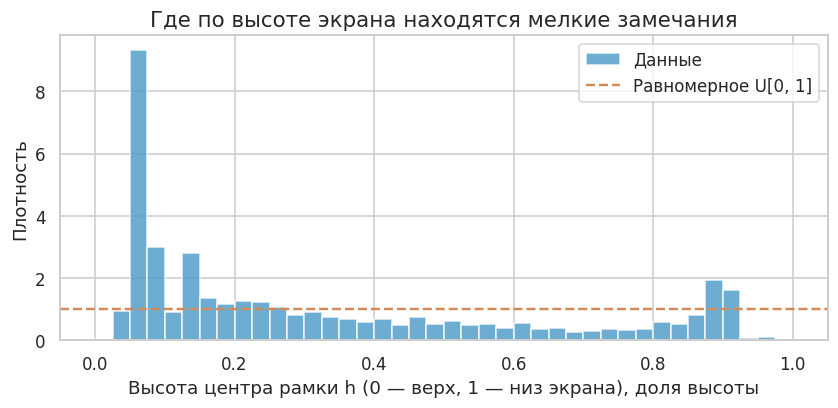

D = 0.303, p = 0.0e+00
В верхних 20% экрана: 49% замечаний (при равномерном было бы 20%)


In [ ]:
h = small["h"]
ks = stats.kstest(h, "uniform")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(h, bins=40, range=(0, 1), density=True, color=C["data"], alpha=.85, edgecolor="white", label="Данные")
ax.axhline(1, color=C["ref"], lw=1.6, ls="--", label="Равномерное U[0, 1]")
ax.set(xlabel="Высота центра рамки h (0 — верх, 1 — низ экрана), доля высоты",
       ylabel="Плотность", title="Где по высоте экрана находятся мелкие замечания")
ax.legend()
plt.show()

print(f"D = {ks.statistic:.3f}, p = {ks.pvalue:.1e}")
print(f"В верхних 20% экрана: {(h < 0.2).mean():.0%} замечаний (при равномерном было бы 20%)")

**Вывод.** Замечания распределены по высоте экрана совсем не равномерно (D = 0.30, p ≈ 0). Почти половина из них — в верхней пятой части экрана, хотя при равномерном распределении было бы 20%. Второй, меньший пик — внизу, у навигации.

#### 5.5.2. Указывают ли люди и ИИ на одну и ту же высоту?

$H_0$: распределения $h$ у замечаний людей и ИИ одинаковы. Критерий Манна-Уитни
(не требует нормальности).

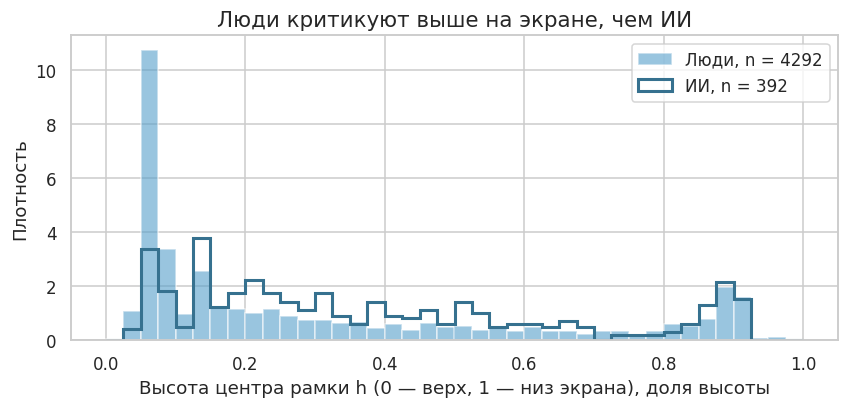

Медиана h: люди 0.17, ИИ 0.31
U = 651560, p = 1.4e-13, r_rb = -0.23
Медианная площадь рамки: люди 0.044, ИИ 0.095 (все рамки)


In [ ]:
h_human = small.loc[small["source"] == "human", "h"]
h_llm = small.loc[small["source"] == "llm", "h"]
mw = stats.mannwhitneyu(h_human, h_llm, alternative="two-sided")
r_rb = 2 * mw.statistic / (len(h_human) * len(h_llm)) - 1      # ранговая бисериальная корреляция

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(h_human, bins=40, range=(0, 1), density=True, color=C["data"], alpha=.6, label=f"Люди, n = {len(h_human)}")
ax.hist(h_llm, bins=40, range=(0, 1), density=True, histtype="step", lw=2, color=C["alt"], label=f"ИИ, n = {len(h_llm)}")
ax.set(xlabel="Высота центра рамки h (0 — верх, 1 — низ экрана), доля высоты",
       ylabel="Плотность", title="Люди критикуют выше на экране, чем ИИ")
ax.legend()
plt.show()

print(f"Медиана h: люди {h_human.median():.2f}, ИИ {h_llm.median():.2f}")
print(f"U = {mw.statistic:.0f}, p = {mw.pvalue:.1e}, r_rb = {r_rb:.2f}")
print(f"Медианная площадь рамки: люди {boxes.loc[boxes['source']=='human','area'].median():.3f}, "
      f"ИИ {boxes.loc[boxes['source']=='llm','area'].median():.3f} (все рамки)")

**Вывод.**
Замечания людей в среднем расположены выше на экране, чем замечания ИИ (медиана — 17% высоты против 31%, p ≈ 1·10⁻¹³). Разница не очень большая, но устойчивая (проверка в 5.5.4). Ещё у ИИ медианная площадь рамки вдвое больше: его замечания чаще касаются целого блока, а люди чаще указывают на конкретную кнопку или иконку.

#### 5.5.3. Связана ли тема замечания с зоной экрана?

Зоны: **шапка** — верхние 12% высоты, **низ** — нижние 12%, **контент** — всё между ними.
Здесь каждому замечанию нужна ровно одна тема, поэтому темы назначаем по приоритету
(кнопки → иконки → цвет → текст → другое). $H_0$: тема и зона независимы; критерий $\chi^2$, сила связи — V Крамера.

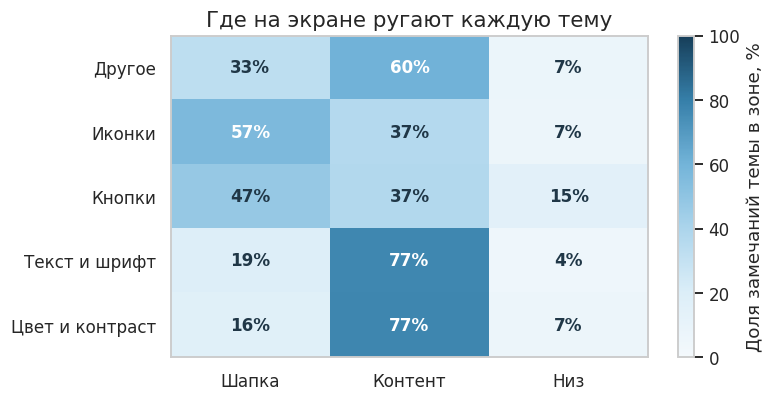

Зона,Шапка,Контент,Низ
Тема,,,
Другое,380,703,82
Иконки,543,352,64
Кнопки,660,522,212
Текст и шрифт,162,659,37
Цвет и контраст,179,855,75


χ² = 773, df = 8, p = 1.2e-161, V Крамера = 0.27, мин. ожидаемая частота = 74


In [ ]:
theme_one = np.select(
    [small["Кнопки"], small["Иконки"], small["Цвет и контраст"], small["Текст и шрифт"]],
    ["Кнопки", "Иконки", "Цвет и контраст", "Текст и шрифт"], "Другое")
zone = pd.cut(small["h"], [0, .12, .88, 1], labels=["Шапка", "Контент", "Низ"], include_lowest=True)
table = pd.crosstab(pd.Series(theme_one, index=small.index, name="Тема"), zone.rename("Зона"))
chi2, p, dof, expected = stats.chi2_contingency(table)
V = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
share = table.div(table.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(share.to_numpy() * 100, cmap=HEAT, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(share.shape[1]), share.columns)
ax.set_yticks(range(share.shape[0]), share.index)
ax.grid(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j] * 100
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=11, fontweight="bold",
                color="white" if v > 55 else C["ink"])
fig.colorbar(im, ax=ax, label="Доля замечаний темы в зоне, %")
ax.set_title("Где на экране ругают каждую тему")
plt.show()

print(f"χ² = {chi2:.0f}, df = {dof}, p = {p:.1e}, V Крамера = {V:.2f}, мин. ожидаемая частота = {expected.min():.0f}")
table

**Вывод.** Тема замечания и место на экране связаны (χ² = 773, p ≈ 0, V Крамера = 0.27 — связь умеренная). Иконки чаще всего ругают в шапке (57%), кнопки — тоже в шапке, но заметно чаще остальных тем и внизу (15%). Текст и цвет в основном обсуждают в контенте (77%). Критерий здесь применим: во всех ячейках таблицы ожидается больше 5 замечаний.

#### 5.5.4. Устойчивость выводов к группировке замечаний

Критерии 5.5.1–5.5.3 считают каждое замечание отдельным наблюдением, но один аннотатор пишет несколько замечаний к одному экрану,
и они зависимы. Проверим два главных вывода на уровне, где наблюдения независимее.

1. **Смещение к верху экрана.** Для каждого экрана считаем долю его мелких замечаний в верхних 20% высоты, затем сравниваем
   среднюю по экранам долю с 20% (равномерный случай) одновыборочным t-критерием. Каждый экран — одно наблюдение.
2. **Люди и ИИ.** Берём аннотаторов (строки датасета), у которых есть и свои мелкие замечания, и принятые замечания ИИ,
   и сравниваем среднюю высоту $h$ тех и других **внутри одного аннотатора** знаковым критерием Уилкоксона.
   Так различия между экранами и аннотаторами не смешиваются с различием «человек — ИИ».

In [ ]:
# 1. Доля мелких замечаний экрана в верхних 20% высоты: одно значение на экран
top_share = small.groupby("rico_id")["h"].apply(lambda s: (s < 0.2).mean())
t_top = stats.ttest_1samp(top_share, 0.2)
print(f"Экранов: {len(top_share)}; средняя доля сверху: {top_share.mean():.0%} (равномерно было бы 20%)")
print(f"t = {t_top.statistic:.1f}, p = {t_top.pvalue:.1e}")

# 2. Люди и ИИ внутри одного аннотатора: средняя высота h замечаний каждого источника
paired = (small[small["source"].isin(["human", "llm"])]
          .groupby(["annotation", "source"])["h"].mean()
          .unstack().dropna())
w = stats.wilcoxon(paired["human"], paired["llm"])
diff = paired["human"] - paired["llm"]
print(f"\nАннотаторов с обоими источниками: {len(paired)}")
print(f"Медиана разности h (люди − ИИ): {diff.median():.3f}; у людей выше на экране в {(diff < 0).mean():.0%} пар")
print(f"Уилкоксон: W = {w.statistic:.0f}, p = {w.pvalue:.1e}")

Экранов: 982; средняя доля сверху: 50% (равномерно было бы 20%)
t = 29.4, p = 1.5e-136

Аннотаторов с обоими источниками: 292
Медиана разности h (люди − ИИ): -0.035; у людей выше на экране в 60% пар
Уилкоксон: W = 15237, p = 2.0e-05


**Вывод.** Мы боялись, что результаты получились такими только потому, что один человек пишет много замечаний к одному экрану. Поэтому перепроверили их по экранам и по отдельным аннотаторам. Оба вывода сохранились: на экранах в среднем половина мелких замечаний находится в верхней пятой части (p ≈ 10⁻¹³⁶), и даже у одного и того же аннотатора его собственные замечания расположены выше, чем принятые им замечания ИИ (p ≈ 2·10⁻⁵). Учесть, что некоторые экраны могут быть из одного приложения, мы не смогли: таких данных в датасете нет.

<a id="heat-limits"></a>
### 5.6. Ограничения

- **Темы — по ключевым словам.** Грубая классификация: часть замечаний попадает не в свою тему или сразу в несколько.
- **Экраны разные** (с клавиатурой и без, разной вёрстки), а накладываем их в одни координаты: карта показывает
  тенденции, а не точные места.
- **Скриншотов нет:** они в отдельном наборе RICO, поэтому под картой только силуэт.
- **Замечания не независимы:** один аннотатор пишет несколько замечаний к одному экрану, поэтому p-value в 5.5.1–5.5.3
  приблизительные. Главные выводы проверены на уровне экранов и аннотаторов в 5.5.4 и сохраняются; группировку экранов
  по приложениям учесть нельзя — она в датасете не указана.
- **Ошибка в данных:** в 83 строках метки автора не совпадают с замечаниями; эти замечания исключены из сравнения людей и ИИ.

<a id="heat-resume"></a>
### 5.7. Выводы по тепловой карте

Тепловая карта показала то, чего мы сначала не ожидали. Мы думали, что больше всего замечаний будет посередине экрана, там, где основной контент. Оказалось наоборот: мелкие проблемы чаще всего находят по краям и в верхних углах, где обычно кнопка «назад» и меню, в шапке и в нижней навигации. Проверка подтвердила, что это не случайность и почти половина мелких замечаний приходится на верхнюю пятую часть экрана, хотя при равномерном распределении было бы 20%.

У каждой темы есть «своё место». Иконки и кнопки ругают в основном в шапке, кнопки — ещё и внизу, а текст и цвет — в контенте. По сути, эксперты чаще всего спотыкаются о навигационные элементы, которые есть почти на каждом экране.

Ещё мы сравнили замечания людей и нейросети. Люди чаще отмечают конкретные элементы вверху экрана, а замечания Gemini обычно ниже и относятся к целым блокам. При этом рамки для замечаний Gemini тоже рисовали люди, так что это разница в том, о чём замечание, а не в том, куда «смотрит» нейросеть.

Для дизайнеров вывод простой: когда они проверяют интерфейс стоит в первую очередь смотреть на края экрана где шапка, иконки и навигация. А в разделе 6 мы проверили, связаны ли такие замечания с тем, как эксперты оценивают экран.

### Методические уточнения к исходному разделу 5

При чтении результатов раздела 5 учитывай следующие уточнения:

- Значения p в обычных тестах по отдельным замечаниям не учитывают зависимость замечаний внутри экрана. Их малость **не гарантирует**, что вывод сохранится после учёта группировки. Результаты этих тестов рассматриваем как предварительные. Проверки раздела 6 используют экранные показатели, но тоже не учитывают неизвестную группировку по приложениям и повторное участие оценщиков.
- «Люди и ИИ смотрят по-разному» не означает различия взгляда: это различия расположения рамок принятых замечаний; рамки для Gemini назначали люди.
- Равномерность центров рамок — геометрическая модель сравнения. Даже случайно размещённые рамки конечного размера не обязательно имеют центры, равномерные на всём [0, 1]; эта проверка не измеряет вероятность дефекта в каждой зоне.
- Выбор мелких рамок ограничивает выводы мелкими замечаниями. Крупная рамка сама по себе не доказывает, что текст относится к «общему впечатлению».
- Медианная площадь и средняя площадь — разные характеристики. Выведенное в разделе 5 сравнение площадей относится к медианам.


<a id="rating-comments"></a>

## **6. Что стоит за оценками: темы и расположение замечаний**

**Вопрос, который мы рассматриваем в этом разделе:** Отличаются ли темы и расположение замечаний у экранов с низкими и высокими средними оценками эстетики и удобства?

В разделе 4 мы обнаружили сильную положительную связь средних
оценок эстетики и удобства. При этом сравнение аннотаций показало,
что восприятие одного экрана может различаться между оценщиками.

В разделе 5 мы исследовали темы и расположение замечаний и обнаружили
концентрацию мелких замечаний в верхней части экрана. Теперь проверим,
различаются ли темы и расположение замечаний у экранов с относительно
низкими и высокими средними оценками.

Эстетику и удобство рассматриваем отдельно. Низкая или высокая средняя
оценка характеризует группу в нашем датасете, но не означает единогласия
оценщиков. Найденные различия описывают связь замечаний с оценками,
а не причины этих оценок.
### **Как читать результаты**

Темы определяем по ключевым словам. Одно замечание может относиться
к нескольким темам, поэтому сумма долей может превышать 100%.
Сначала рассчитываем доли для каждого экрана, затем усредняем их
по группе — каждый экран имеет одинаковый вес.

Используем все замечания: человеческие и принятые людьми замечания
Gemini. Расположение определяем по рамкам, назначенным людьми;
оно не показывает взгляд оценщика или вероятность дефекта.


<a id="rating-groups"></a>
### 6.1. Подготовка и разделение экранов

Для каждого показателя нижняя группа: оценка ≤ Q1; верхняя: оценка ≥ Q3. Равные оценки не разрываем произвольно, поэтому группы могут быть больше 25%. Средние экраны в сравнении крайних групп не участвуют.

Замечания разбираем заново из `df`, сохраняя и тексты без корректной рамки для анализа тем. Для карт оставляем только конечные координаты с 0 ≤ x1 < x2 ≤ 1 и 0 ≤ y1 < y2 ≤ 1. Несовпадения источников не мешают этому анализу: по источникам здесь не разделяем.


In [ ]:
import ast
import re

link_records = []
link_parse_errors = 0
link_box_pattern = re.compile(r"Bounding\s+Box:\s*\[([^\]]+)\]", re.I)
link_patterns = {
    "Цвет и контраст": r"\b(?:colou?r|contrast)\b",
    "Текст и шрифт": r"\bfont\w*\b|\btext\s+size\b|\breadab\w*\b",
    "Кнопки": r"\bbutton\w*\b",
    "Иконки": r"\bicon\w*\b",
}
for _, row in df.iterrows():
    try:
        comments_list = ast.literal_eval(row["comments"])
        if not isinstance(comments_list, list):
            raise ValueError("Ожидался список")
    except (ValueError, SyntaxError, TypeError):
        link_parse_errors += 1
        continue
    for comment in comments_list:
        if not isinstance(comment, str):
            continue
        text_only = link_box_pattern.sub("", comment).lower()
        record = {"rico_id": row["rico_id"], "text": text_only,
                  "valid_box": False, "x1": np.nan, "y1": np.nan,
                  "x2": np.nan, "y2": np.nan}
        match = link_box_pattern.search(comment)
        if match:
            try:
                coordinates = np.array([float(z) for z in match.group(1).split(",")])
                if len(coordinates) == 4 and np.isfinite(coordinates).all():
                    x1, y1, x2, y2 = coordinates
                    if 0 <= x1 < x2 <= 1 and 0 <= y1 < y2 <= 1:
                        record.update(valid_box=True, x1=x1, y1=y1, x2=x2, y2=y2)
            except ValueError:
                pass
        for theme, pattern in link_patterns.items():
            record[theme] = bool(re.search(pattern, text_only))
        link_records.append(record)

link_comments = pd.DataFrame(link_records)
link_comments["area"] = ((link_comments.x2 - link_comments.x1)
                         * (link_comments.y2 - link_comments.y1))
link_theme_columns = list(link_patterns)
link_screen_shares = link_comments.groupby("rico_id")[link_theme_columns].mean()
link_counts = link_comments.groupby("rico_id").size().rename("n_comments")
link_screens = screens.merge(link_screen_shares, on="rico_id", how="left").merge(
    link_counts, on="rico_id", how="left")
link_metrics = {"Эстетика": "aesthetics_mean", "Удобство": "usability_mean"}
link_groups, link_group_rows = {}, []
for metric_name, metric_column in link_metrics.items():
    q_low, q_high = link_screens[metric_column].quantile([.25, .75])
    if not q_low < q_high:
        raise ValueError("Квартильные границы совпали: группы требуют другого правила")
    low_ids = link_screens.loc[link_screens[metric_column] <= q_low, "rico_id"]
    high_ids = link_screens.loc[link_screens[metric_column] >= q_high, "rico_id"]
    link_groups[metric_name] = {"Низкие": set(low_ids), "Высокие": set(high_ids)}
    assert set(low_ids).isdisjoint(set(high_ids))
    for group_name, ids in link_groups[metric_name].items():
        subset = link_screens[link_screens.rico_id.isin(ids)]
        link_group_rows.append({"Показатель": metric_name, "Группа": group_name,
            "Граница": q_low if group_name == "Низкие" else q_high,
            "Экранов": len(subset), "С замечаниями": int(subset.n_comments.notna().sum()),
            "Замечаний": int(subset.n_comments.sum())})
print("Строк с ошибкой разбора:", link_parse_errors)
print("Всего замечаний:", len(link_comments))
print("С корректной рамкой:", int(link_comments.valid_box.sum()))
display(pd.DataFrame(link_group_rows))

,Показатель,Группа,Граница,Экранов,С замечаниями,Замечаний
0,Эстетика,Низкие,5.333333,322,322,3918
1,Эстетика,Высокие,6.333333,259,259,2714
2,Удобство,Низкие,5.333333,292,292,3668
3,Удобство,Высокие,6.333333,284,284,2823


Строк с ошибкой разбора: 0
Всего замечаний: 11430
С корректной рамкой: 11430


#### Вывод о составе групп

Группы получились примерно одинаковыми по количеству экранов, самая большая группа получилась с низкими оценками эстетики. Границы низких и высоких средних оценок совпали для эстетики и удобства: 5,33 и 6,33 балла соответственно. Размеры групп различаются из-за повторяющихся оценок на границах квартилей, поэтому также мы получили не четверть датасета. Также все группы имеют какие-то замечания. В группах низких оценок среднее число замечаний на экран выше, однако статистическая значимость этого различия пока не проверялась


<a id="rating-themes"></a>
### 6.2. Какие темы встречаются в замечаниях

Для экрана доля темы — число его замечаний с соответствующими ключевыми словами, делённое на общее число его замечаний. На графике — средняя этих долей по экранам группы. Например, 20% означает среднюю долю замечаний данной темы внутри экрана, а не долю плохих экранов.

Горизонтальные отрезки — 95%-е процентильные bootstrap-интервалы: повторно выбираем экраны с возвращением внутри каждой группы. Они условны на выбранных группах и предполагают независимость экранов. Связь экранов одного приложения и повторное участие оценщиков этим не учитываются. Перекрытие интервалов само по себе не является тестом различий.


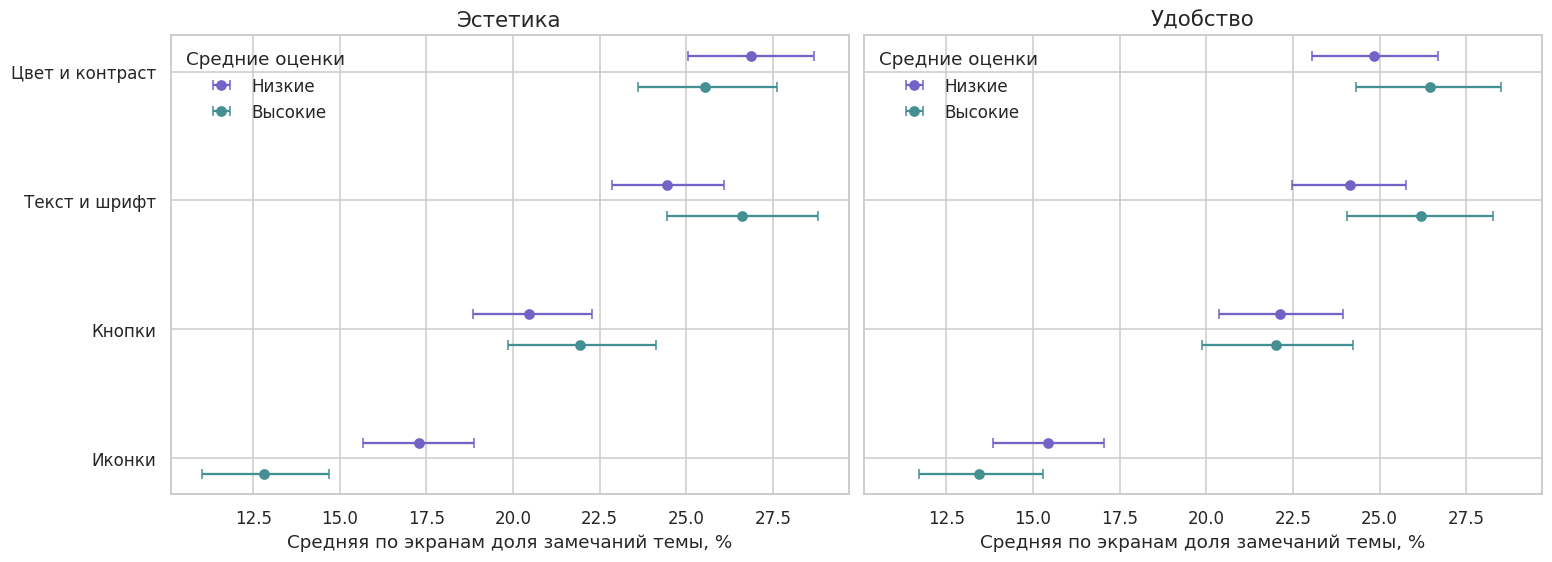

,Показатель,Группа,Тема,"Средняя доля, %","Нижняя граница, %","Верхняя граница, %",Экранов
0,Эстетика,Низкие,Цвет и контраст,26.85,25.06,28.69,322
1,Эстетика,Низкие,Текст и шрифт,24.45,22.86,26.09,322
2,Эстетика,Низкие,Кнопки,20.47,18.85,22.28,322
3,Эстетика,Низкие,Иконки,17.28,15.67,18.86,322
4,Эстетика,Высокие,Цвет и контраст,25.55,23.60,27.60,259
5,Эстетика,Высокие,Текст и шрифт,26.62,24.45,28.79,259
6,Эстетика,Высокие,Кнопки,21.93,19.84,24.12,259
7,Эстетика,Высокие,Иконки,12.81,11.01,14.68,259
8,Удобство,Низкие,Цвет и контраст,24.84,23.05,26.68,292
9,Удобство,Низкие,Текст и шрифт,24.16,22.47,25.77,292


In [ ]:
link_rng = np.random.default_rng(42)
link_theme_rows = []
for metric_name, groups in link_groups.items():
    for group_name, ids in groups.items():
        subset = link_screens[link_screens.rico_id.isin(ids)]
        for theme in link_theme_columns:
            values = subset[theme].dropna().to_numpy(float)
            boot = np.array([link_rng.choice(values, len(values), replace=True).mean()
                             for _ in range(2000)])
            ci_low, ci_high = np.quantile(boot, [.025, .975])
            link_theme_rows.append({"Показатель": metric_name, "Группа": group_name,
                "Тема": theme, "Средняя доля, %": 100 * values.mean(),
                "Нижняя граница, %": 100 * ci_low, "Верхняя граница, %": 100 * ci_high,
                "Экранов": len(values)})
link_theme_summary = pd.DataFrame(link_theme_rows)
link_colors = {"Низкие": "#7463C7", "Высокие": "#438F92"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, metric_name in zip(axes, link_metrics):
    for offset, group_name in [(-.12, "Низкие"), (.12, "Высокие")]:
        part = link_theme_summary[(link_theme_summary.Показатель == metric_name)
                                  & (link_theme_summary.Группа == group_name)]
        center = part["Средняя доля, %"].to_numpy()
        error = np.vstack([center - part["Нижняя граница, %"].to_numpy(),
                           part["Верхняя граница, %"].to_numpy() - center])
        ax.errorbar(center, np.arange(len(part)) + offset, xerr=error,
                    fmt="o", capsize=3, color=link_colors[group_name], label=group_name)
    ax.set(title=metric_name, xlabel="Средняя по экранам доля замечаний темы, %")
    ax.set_yticks(range(len(link_theme_columns)), link_theme_columns)
    ax.legend(title="Средние оценки", frameon=False)
axes[0].invert_yaxis()
plt.show()
display(link_theme_summary.round(2))

#### **Вывод о теме замечаний**

Наибольшую долю замечаний в группах низких оценок составляют замечания о цвете и контрасте: для эстетики — 26,85%, для удобства — 24,84%. Касаемо высоких оценок чаще всего встречается у эстетики текст и шрифт, а в удобстве почти наравне идут цвет и контраст с текстом и шрифтом(типографика сайта зачастую действительно играет большую роль, по крайней мере из собственного опыта). Снова видно то, насколько похожи эстетика и удобство по показателям и визуально, Наиболее заметное различие между низкой и высокой группами наблюдается для иконок по эстетике — 4,47 процентного пункта, хотя по удобству оно направлено в ту же сторону, но меньше — 1,99 п.п.



<a id="rating-tests"></a>
### **6.3 Проверка различий между группами**

Для каждой темы и каждого показателя проверяем нулевую гипотезу об одинаковом распределении экранных долей в низкой и высокой группах. Статистика — разность средних долей (низкие минус высокие). Переставляем групповые метки между экранами; отдельные замечания не считаем независимыми наблюдениями.

Проверка двусторонняя, 4999 перестановок, α = 0,05. Для восьми сравнений применяем поправку Холма. Минимальная Monte Carlo оценка p-value равна 1/5000. Это исследовательские сравнения, а не причинный эксперимент. Экраны считаются независимыми и обменными при нулевой гипотезе; неизвестная группировка по приложениям и оценщикам остаётся ограничением.


In [ ]:
link_test_rng = np.random.default_rng(2026)
link_test_rows = []
for metric_name, groups in link_groups.items():
    low = link_screens[link_screens.rico_id.isin(groups["Низкие"])]
    high = link_screens[link_screens.rico_id.isin(groups["Высокие"])]
    for theme in link_theme_columns:
        first, second = low[theme].dropna().to_numpy(), high[theme].dropna().to_numpy()
        observed = first.mean() - second.mean()
        pool = np.r_[first, second]
        extreme = 0
        for _ in range(4999):
            shuffled = link_test_rng.permutation(pool)
            difference = shuffled[:len(first)].mean() - shuffled[len(first):].mean()
            extreme += abs(difference) >= abs(observed) - 1e-12
        link_test_rows.append({"Показатель": metric_name, "Тема": theme,
            "Разность низкие − высокие, п.п.": observed * 100,
            "p-value": (extreme + 1) / 5000})
link_tests = pd.DataFrame(link_test_rows)
p_values = link_tests["p-value"].to_numpy()
order = np.argsort(p_values)
adjusted_order = np.minimum(1, np.maximum.accumulate(
    (len(p_values) - np.arange(len(p_values))) * p_values[order]))
adjusted = np.empty(len(p_values)); adjusted[order] = adjusted_order
link_tests["p-value Холма"] = adjusted
link_tests["Отвергаем H₀ при 0,05"] = adjusted < .05
display(link_tests.round(4))

,Показатель,Тема,"Разность низкие − высокие, п.п.",p-value,p-value Холма,"Отвергаем H₀ при 0,05"
0,Эстетика,Цвет и контраст,1.3032,0.3534,1.0000,False
1,Эстетика,Текст и шрифт,-2.1664,0.1188,0.7896,False
2,Эстетика,Кнопки,-1.4670,0.2978,1.0000,False
3,Эстетика,Иконки,4.4619,0.0006,0.0048,True
4,Удобство,Цвет и контраст,-1.6236,0.2620,1.0000,False
5,Удобство,Текст и шрифт,-2.0236,0.1510,0.7896,False
6,Удобство,Кнопки,0.1106,0.9414,1.0000,False
7,Удобство,Иконки,1.9959,0.1128,0.7896,False


#### **Вывод о проверке различий**

Тут мы видим, что p-value с поправкой Холма меньше 0,05 только у иконок, конкретно у эстетики, поэтому это единственный случай, где мы отвергаем H₀. Это значит, что статистически значимое различие обнаружено только для одной темы замечаний: в группе низких средних оценок эстетики доля замечаний об иконках выше на 4,46 процентного пункта, чем в группе высоких. Для остальных тем, а также для всех тем по удобству, различие не подтвердилось.

### **6.4 Расположение замечаний и его связь с оценкой**

Вместо тепловых карт используем две статические панели: сначала для эстетики, затем для удобства. В обеих — одинаковые шкалы.

**Слева:** экран делится на десять полос по высоте. Замечание относим к полосе по центру его рамки. Сначала считаем доли замечаний по полосам отдельно для каждого экрана, затем усредняем внутри группы низких или высоких оценок. Крупнее число по горизонтали — больше средняя доля замечаний в полосе. Верх рисунка соответствует верху экрана. Это распределение центров, а не карта покрытия рамками из раздела 5.

**Справа:** одна точка — один экран. X — его средняя оценка; Y — доля его мелких замечаний с центром в верхних 20% высоты. Здесь используются все экраны с подходящими рамками, включая среднюю группу. Порог верхней зоны 20% — описательный выбор, а не естественная граница интерфейса. Коэффициент Спирмена подписан как характеристика связи; отдельное подтверждающее тестирование по этому графику не проводится.

Берём только корректные рамки площадью менее 5%. Экраны без подходящих рамок исключаются, а не получают нулевую долю. Размеры групп показаны в таблице. Один экран имеет одинаковый вес независимо от количества замечаний. Сходные координаты не означают одинаковых элементов. Различия не доказывают причину низкой или высокой оценки.


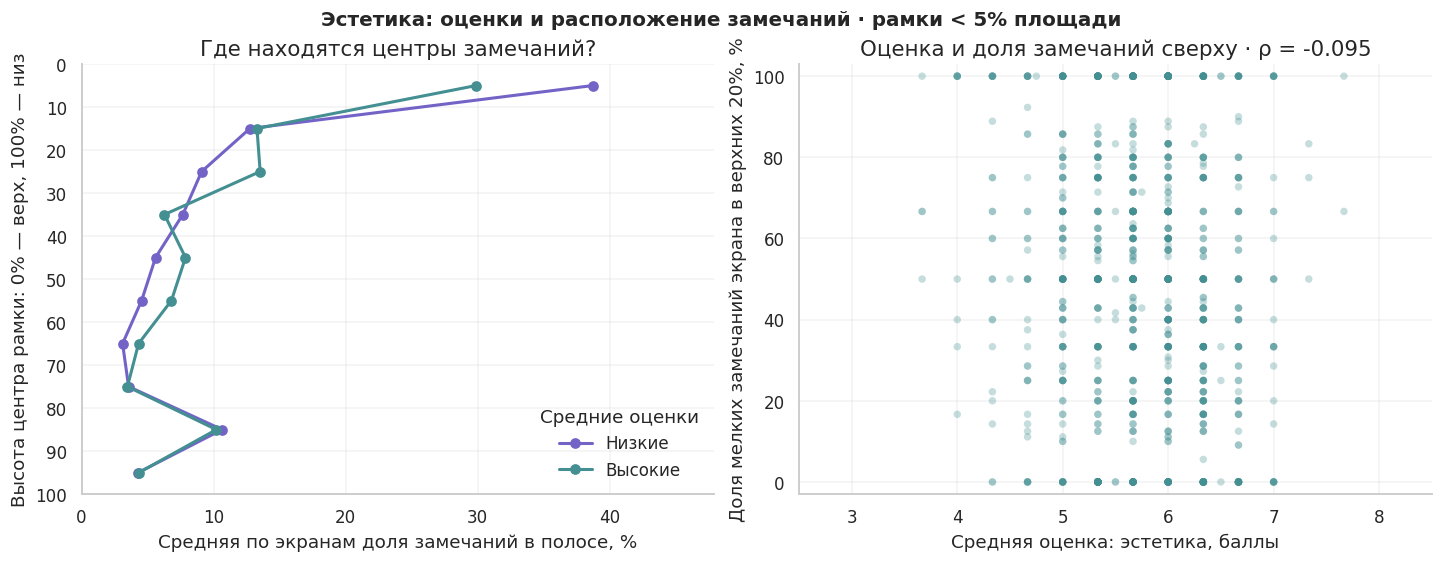

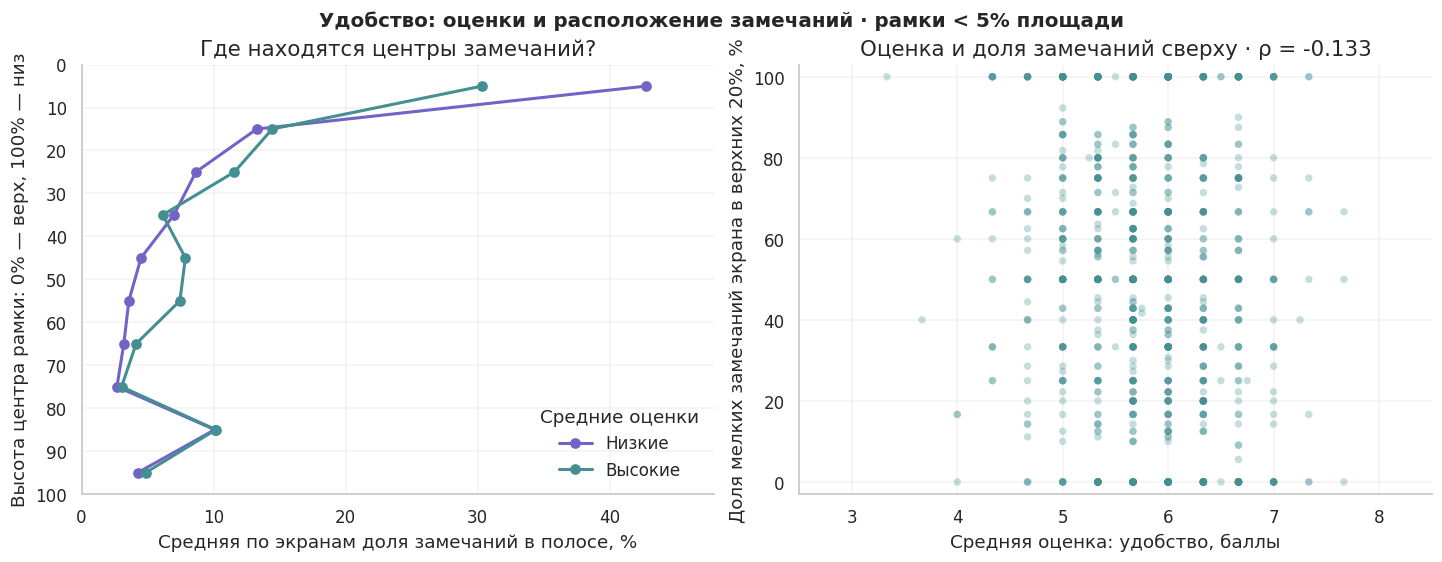

,Показатель,Группа,Всего экранов,В профиле,Без подходящих рамок
0,Эстетика,Низкие,322,316,6
1,Эстетика,Высокие,259,258,1
2,Удобство,Низкие,292,288,4
3,Удобство,Высокие,284,280,4


В облаках: 982 экранов из 1000
Совпадающие точки могут накладываться; значения не сдвигаются.


In [ ]:
# Статические профили и облака точек: без виджетов и тепловых карт.
link_height_bins = np.linspace(0, 1, 11)
link_height_centers = (link_height_bins[:-1] + link_height_bins[1:]) / 2

def link_location_data(area_limit=.05):
    selected = link_comments[
        link_comments.valid_box & (link_comments.area < area_limit)
    ].copy()
    selected["center_y"] = (selected.y1 + selected.y2) / 2
    profiles, screen_rows = {}, []
    for screen_id, group in selected.groupby("rico_id"):
        heights = group.center_y.to_numpy()
        profiles[screen_id] = np.histogram(heights, bins=link_height_bins)[0] / len(heights)
        screen_rows.append({"rico_id": screen_id,
                           "upper_share": (heights < .2).mean(),
                           "n_small_comments": len(heights)})
    summary = pd.DataFrame(screen_rows).merge(
        screens[["rico_id", "aesthetics_mean", "usability_mean"]], on="rico_id")
    return profiles, summary

link_profiles, link_location_screens = link_location_data()
link_profile_results, link_coverage_rows = {}, []
for metric_name, groups in link_groups.items():
    for group_name, ids in groups.items():
        included = [link_profiles[i] for i in ids if i in link_profiles]
        link_profile_results[(metric_name, group_name)] = np.mean(included, axis=0) * 100
        link_coverage_rows.append({"Показатель": metric_name, "Группа": group_name,
            "Всего экранов": len(ids), "В профиле": len(included),
            "Без подходящих рамок": len(ids)-len(included)})
link_profile_max = max(values.max() for values in link_profile_results.values()) * 1.12
link_plot_lower = max(1, np.floor(link_location_screens[list(link_metrics.values())].min().min())-.5)
link_plot_upper = min(10, np.ceil(link_location_screens[list(link_metrics.values())].max().max())+.5)

for metric_name, metric_column in link_metrics.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for group_name in ["Низкие", "Высокие"]:
        axes[0].plot(link_profile_results[(metric_name, group_name)],
                     link_height_centers * 100, marker="o", linewidth=2,
                     color=link_colors[group_name], label=group_name)
    axes[0].set(title="Где находятся центры замечаний?",
        xlabel="Средняя по экранам доля замечаний в полосе, %",
        ylabel="Высота центра рамки: 0% — верх, 100% — низ",
        xlim=(0, link_profile_max), ylim=(100, 0))
    axes[0].set_yticks(np.arange(0, 101, 10))
    axes[0].legend(title="Средние оценки", frameon=False)
    coefficient = stats.spearmanr(link_location_screens[metric_column],
                                 link_location_screens.upper_share).statistic
    axes[1].scatter(link_location_screens[metric_column],
                    link_location_screens.upper_share * 100,
                    s=24, alpha=.3, color="#438F92", edgecolors="none")
    axes[1].set(title=f"Оценка и доля замечаний сверху · ρ = {coefficient:.3f}",
        xlabel=f"Средняя оценка: {metric_name.lower()}, баллы",
        ylabel="Доля мелких замечаний экрана в верхних 20%, %",
        xlim=(link_plot_lower, link_plot_upper), ylim=(-3, 103))
    for ax in axes:
        ax.grid(alpha=.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    fig.suptitle(f"{metric_name}: оценки и расположение замечаний · рамки < 5% площади",
                 fontsize=13, fontweight="bold")
    plt.show()
print("В облаках:", len(link_location_screens), "экранов из", len(screens))
print("Совпадающие точки могут накладываться; значения не сдвигаются.")
display(pd.DataFrame(link_coverage_rows))

#### **Вывод о расположении замечаний**

В основном замечания расположены в верхней части экрана, если мы посмотрим на левые 2 графика. У удобства сосредоточенность низких оценок побольше, но при этом профили графиков также сильно похожи между собой.

Если мы посмотрим на правые графики, то увидим, что облако на обоих графиках получилось достаточно размашистым, а связь средней оценки с долей замечаний в верхних 20% экрана слабая и отрицательная: для эстетики коэффициент Спирмена составляет -0,095, для удобства - -0,133, поэтому высокая доля замечаний сверху сама по себе не указывает на низкую оценку экрана.

Из этого если мы посмотрим на раздел 5, где видно, что мелкие замечания часто расположены сверху, то сейчас мы видим, что верхняя часть экрана выделяется и при низких, и при высоких средних оценках


<a id="rating-explorer"></a>

### **6.5 Проверка чувствительности к порогу площади**

Сравним профили всех экранов при порогах 3%, 5% и 10% площади. Каждый экран с подходящими рамками имеет одинаковый вес. Состав включённых экранов при смене порога меняется; фактическое число показано в легенде.

Это статическая проверка того, насколько выбор 5% влияет на описание расположения замечаний. Если кривые расходятся, вывод зависит от порога. Переключение эстетики и удобства можно добавить позже на сайте; в ноутбуке результаты показаны отдельно.


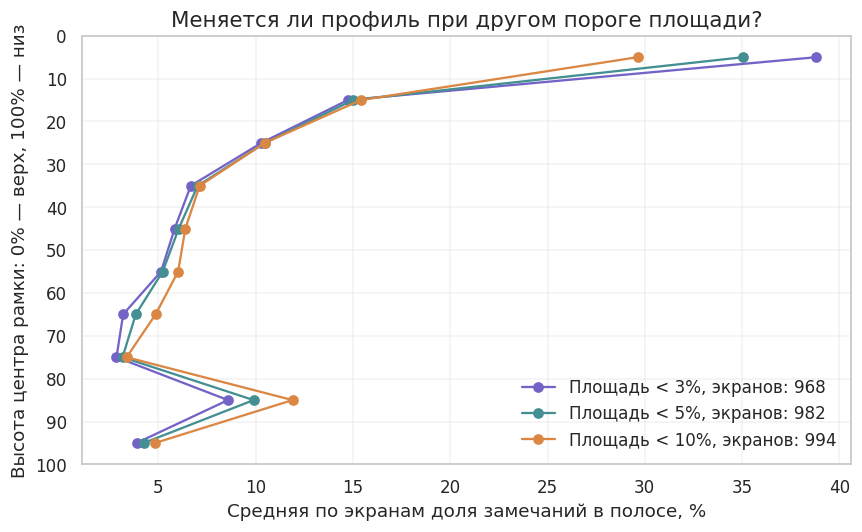

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for limit, color in [(.03, "#7463C7"), (.05, "#438F92"), (.10, "#DB8744")]:
    profiles, summary = link_location_data(limit)
    mean_profile = np.mean(list(profiles.values()), axis=0) * 100
    ax.plot(mean_profile, link_height_centers * 100, marker="o", color=color,
            label=f"Площадь < {limit:.0%}, экранов: {len(summary)}")
ax.set(title="Меняется ли профиль при другом пороге площади?",
       xlabel="Средняя по экранам доля замечаний в полосе, %",
       ylabel="Высота центра рамки: 0% — верх, 100% — низ",
       ylim=(100, 0))
ax.set_yticks(np.arange(0, 101, 10))
ax.grid(alpha=.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### **Вывод о выбранном пороге площади**

Чтобы исключить то, что результаты были сосредоточены в верхней части экрана из-за выбранного размера 5% мы разобрали случаи при порогах площади 3%, 5% и 10%. Общая форма профиля сохранилась, тк мелкие замечания преимущественно сосредоточены сверху, с дополнительным пиком внизу. Следовательно, эта особенность не возникает исключительно из-за выбора порога 5%, но при этом меняются как доли замечаний, так и состав включённых экранов.

###**Общие выводы: чем сопровождаются оценки**

В целом состав тем замечаний в группах низких и высоких средних оценок похож(как и в целом большинство показателей по эстетике и удобству в этой лабораторной). После поправки Холма статистически значимое различие обнаружено только для темы иконок по эстетике: оно показало, что в низкой группе средняя доля таких замечаний выше на 4,46 процентного пункта. Для остальных сравнений различия статистически не подтверждены

Мелкие замечания сосредоточены сверху и при низких, и при высоких оценках. В низких группах концентрация у самого верха выражена сильнее, однако связь оценки с долей замечаний в верхних 20% слабая, и при изменении порога площади рамок с 3% до 10% общая форма профиля сохраняется. Таким образом, концентрация замечаний сверху является общей особенностью исследуемых экранов.

## **Резюме лабораторной**

В этой работе мы исследовали датасет UICrit и две случайные величины -
средние оценки эстетики и удобства случайно выбранного экрана

Нашей главной гипотезой лабораторной стала связь эстетики и удобства: чем выше средняя оценка эстетики экрана, тем, как правило, выше средняя оценка его удобства. И по итогу мы подтвердили нашу гипотезу. Изначально мы проанализировали случайные величины эстетики и удобства и поняли, что значения и визуально, и численно похожи между собой, но при этом они не поддавались нормальности: это нам показал тест Шапиро — Уилка, а численное сравнение нормальной и бета-модели показало, что бета-модель описывает данные лишь немного лучше

Но похожести данных недостаточно, поэтому саму по себе зависимость мы проанализировали с помощью графика средних оценок(там была замечена как раз зависимость эстетики и удобства, тк если были показатели эстетики выше, то и у удобства тоже), и численно убедились с помощью матрицы корреляции, где связь показателей также дала положительную связь, причем достаточно уверенную. При этом оказалось, что эта связь сильная внутри оценок одного аннотатора и почти исчезает, если сравнивать оценки разных аннотаторов одного экрана

Затем из этого мы перешли к исследованию следующего вопроса - где расположены замечания к интерфейсам. Тепловые карты показали, что мелкие замечания часто сосредоточены в верхней части экрана, с дополнительным пиком внизу

Далее, когда мы определились с расположением замечаний, мы перешли к тому, отличаются ли темы и расположение замечаний
у экранов с низкими и высокими средними оценками. В целом состав тем
оказался похож - в целом на протяжении исследования наблюдалась поразительная схожесть у показателей, что интересно! После поправки Холма статистически значимое различие обнаружилось только для иконок по эстетике, для остальных тем различия статистически не подтвердились. Также выяснилось, что основная тема замечаний стала касаться цветов и контрастов в нижней группе, в верхней у эстетики - текст и шрифт, а основная сосредоточенность в верхней части экрана, причем независимо от порога площади рамок

Таким образом, наша гипотеза получила статистическую поддержку: чем выше средняя оценка эстетики экрана, тем обычно выше оценка его удобства, хотя эта связь проявляется прежде всего в оценках одного человека. При этом темы и расположение замечаний в низких и высоких группах в основном похожи, а наиболее заметное подтверждённое различие - более высокая доля замечаний об иконках у экранов с низкой оценкой эстетики

Надеюсь, вам понравилось изучать это вместе с нами, спасибо!! :)

<a id="literature"></a>

### **Литература и источники**

1. Google Research. UICrit Dataset — данные и описание столбцов.
   https://github.com/google-research-datasets/uicrit

2. Duan P., Chen C., Li G., Hartmann B., Li Y.
   UICrit: Enhancing Automated Design Evaluation with a UI Critique Dataset.
   2024. https://arxiv.org/abs/2407.08850

3. Deka B. et al. Rico: A Mobile App Dataset for Building Data-Driven Design Applications // UIST 2017.

4. Документация SciPy: `scipy.stats.kstest`, `mannwhitneyu`, `chi2_contingency`.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| Доп. КТвД: отдельный датасет и две случайные величины | [1](#data) · [2](#random) | — | Датасет UICrit; средняя оценка эстетики и средняя оценка удобства экрана |
| Доп. КТвД: обоснование случайной природы | [2](#random) | — | Описан случайный выбор экрана и соответствующие ему значения двух величин |
| Доп. КТвД: исследование зависимости | [4](#dependence) | — | Диаграмма рассеяния, корреляции Пирсона и Спирмена, перестановочная проверка независимости |
| Доп. КТвД: EDA | [1](#data) · [3](#eda) | — | Проверка качества данных, описательные статистики, гистограммы с моделями, boxplot, Q–Q и выводы |
| Корректность масштабов и единиц измерения | Графики разделов [3](#eda)–[5](#heatmap) | — | Подписаны оси и единицы; плотность отделена от количества наблюдений; для парных оценок используются одинаковые масштабы осей |
| Единая стилистика графиков | [3](#eda)–[5](#heatmap) | — | Согласованы оформление, цвета и структура панелей |
| Математические формулы в LaTeX | [2](#random) · [5](#heatmap) | — | Формулы средних оценок оформлены в LaTeX |
| Список литературы | [Литература и источники](#literature) | — | Источник датасета, статьи авторов UICrit и RICO, документация SciPy |
| EDA: рамки замечаний | [5.1–5.2](#heat-boxes) | — | Разбор рамок, проверка координат, распределение площади, выбор порога 5% |
| Визуализация: тепловая карта | [5.3–5.4](#heat-main) | — | Доля замечаний по клеткам экрана, сравнение людей и ИИ и тем на общей шкале |
| Проверка гипотез | [5.5](#heat-tests) | — | КС против равномерного, Манн-Уитни (люди и ИИ), χ² и V Крамера (тема × зона) |
| Интерактивность | [5.4](#heat-compare) | — | Переключатели автора и темы, слайдер порога размера рамки |
| Связь основного и дополнительного анализа | [6](#rating-comments) | — | Сравнение тем и профилей расположения замечаний в группах средних оценок |
| Проверка различий | [6.3](#rating-tests) | — | Перестановки на уровне экранов, поправка Холма на восемь сравнений |
| Проверка чувствительности | [6.5](#rating-explorer) | — | Статическое сравнение профилей при порогах 3%, 5% и 10%; интерактив отложен до сайта |